# Deteksi URL Phishing - AUC Dua Arah, RFE, dan XGBoost
Andrian Cheniago - 231111011 | Thienry - 231110743

Notebook ini dimulai dari pemahaman bisnis dan protokol, lalu eksplorasi train dan seleksi AUC dua arah. Setelah XGBoost dituning, seleksi AUC dibandingkan dengan RFE. Bagian berikutnya memuat XGBoost library dan NumPy, baseline Decision Tree, learning curve, SMOTE, dan kesimpulan.

- Label asli 0 berarti phishing dan 1 berarti legitimate. Metrik menghitung phishing sebagai kelas positif.
- Train, validation, dan test dipisahkan per domain induk. Seleksi fitur hanya belajar dari train, validation dipakai saat pengembangan, dan test dipakai untuk laporan akhir setelah desain dibekukan.
- Filter AUC dua arah di sini dipakai untuk membatasi dominasi, jadi yang dibuang adalah fitur dengan AUC terlalu tinggi. Filter konvensional biasanya membuang fitur lemah. AUC yang tinggi saja tidak membuktikan leakage.
- RFE memilih jumlah fitur yang sama dengan AUC dari kumpulan kandidat yang sama, dan skor referensi dikeluarkan dari kedua metode. Model penilai dan split-nya juga sama.
- Decision Tree tanpa batas menjadi baseline, jadi tidak ada baseline duplikat yang ditambahkan.
- Learning curve ukuran data memakai 3-fold GroupKFold pada train, dengan seleksi, imputasi, dan scaling yang diulang di tiap subset. Kurva jumlah pohon juga tersedia. Test tidak dipakai untuk diagnosis atau tuning.
- Acuan notebook adalah Laporan_Milestone_1_Humanize_dan_Daftar_Pustaka.docx di folder UTS. Gunakan kernel `.venv-laporan`, lalu Restart Kernel dan Run All. Versi pustaka, hash CSV, pembagian domain, fitur, learning rate, dan metrik diperiksa terhadap acuan. Angka tetap dihitung dari pelatihan; waktu eksekusi dapat berbeda antarperangkat.

Persiapan sekali melalui PowerShell di folder UTS: `./Siapkan_Environment_Laporan.ps1`. Di VS Code pilih Select Kernel > Python Environments > `.venv-laporan/Scripts/python.exe`. Hasil run baru masuk ke `hasil_revisi`; folder `Enviroment` menyimpan run lama yang berbeda dari laporan.


In [1]:
# Periksa environment sebelum mengimpor pustaka pemodelan.
import sys
import importlib.metadata as metadata
from pathlib import Path

REFERENCE_VERSIONS = {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'tldextract': '5.1.2'}
installed_versions = {"python": sys.version.split()[0]}
for package in REFERENCE_VERSIONS:
    if package != "python":
        try:
            installed_versions[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            installed_versions[package] = "belum terpasang"
mismatches = {name: (installed_versions[name], wanted)
              for name, wanted in REFERENCE_VERSIONS.items()
              if installed_versions[name] != wanted}
if mismatches:
    details = "\n".join(f"- {name}: {got}; perlu {want}" for name, (got, want) in mismatches.items())
    raise RuntimeError(
        "Kernel belum sesuai laporan.\n" + details +
        "\nJalankan Siapkan_Environment_Laporan.ps1 di folder UTS, pilih kernel "
        ".venv-laporan/Scripts/python.exe, lalu Restart Kernel dan Run All."
    )

# Mendukung notebook dibuka dari folder UTS, folder proyek, atau kernel venv UTS.
candidate_dirs = [Path.cwd(), Path.cwd() / "UTS", Path(sys.executable).resolve().parents[2]]
NOTEBOOK_DIR = next((p.resolve() for p in candidate_dirs
                     if (p / "XGBoost_Gabungan_Humanize.ipynb").is_file()), None)
if NOTEBOOK_DIR is None:
    raise FileNotFoundError("Buka notebook dari folder UTS atau pilih kernel .venv-laporan di UTS.")
print("Kernel:", sys.executable)
print("Folder notebook:", NOTEBOOK_DIR)
print("Environment pemodelan sesuai laporan.")


Kernel: D:\mikroskil\MachineLearning\UTS\.venv-laporan\Scripts\python.exe
Folder notebook: D:\mikroskil\MachineLearning\UTS
Environment pemodelan sesuai laporan.


### Persiapan: impor, konfigurasi, dan fungsi bantu
Environment mengikuti tabel pada laporan Humanize. Gunakan `requirements-laporan.txt` di folder UTS; `requirements.txt` di folder utama adalah acuan versi lama. Sel pertama menghentikan eksekusi jika kernel tidak sesuai.
XGBoost memakai 300 pohon, kedalaman 6, learning rate 0,3, λ = 1, min_child_weight = 1, γ = 0, base_score = 0,5, dan `tree_method="exact"` tanpa sampling baris atau kolom. Learning rate 0,3 adalah nilai bawaan XGBoost dan dikonfirmasi dengan validation pada Langkah 3.2. Konfigurasi exact tanpa sampling dipakai agar implementasi NumPy pada Bagian 4 dapat dibandingkan secara numerik dengan library.


In [2]:
from dataclasses import dataclass
from pathlib import Path
from urllib.parse import urlsplit
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tldextract
from IPython.display import display
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, log_loss, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier

@dataclass
class Config:
    dataset: Path = NOTEBOOK_DIR / "phiusiil+phishing+url+dataset/PhiUSIIL_Phishing_URL_Dataset.csv"
    seed: int = 42
    target: str = "label"
    auc_thresholds: tuple = (0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00)  # kandidat ambang Bagian 2
    learning_rates: tuple = (0.005, 0.05, 0.1, 0.3, 0.5)                # kandidat Langkah 3.2
    n_estimators: int = 300
    max_depth: int = 6
    learning_rate: float = 0.3
    reg_lambda: float = 1.0
    min_child_weight: float = 1.0
    base_score: float = 0.5
    target_recall: float = 0.95      # target bisnis (phishing positif)
    target_precision: float = 0.95
    target_fpr: float = 0.05

cfg = Config()
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
COLOR_PHISHING, COLOR_LEGIT = "#d97706", "#0284c7"


def make_xgb(**changes):
    # XGBoost library: exact split tanpa sampling agar dapat direproduksi oleh NumPy (Bagian 4).
    params = dict(n_estimators=cfg.n_estimators, max_depth=cfg.max_depth, learning_rate=cfg.learning_rate,
                  reg_lambda=cfg.reg_lambda, min_child_weight=cfg.min_child_weight, base_score=cfg.base_score,
                  gamma=0.0, subsample=1.0, colsample_bytree=1.0, tree_method="exact",
                  objective="binary:logistic", eval_metric="logloss", importance_type="gain",
                  random_state=cfg.seed, n_jobs=4)
    params.update(changes)
    return XGBClassifier(**params)


def phishing_probability(model, matrix):
    # Probabilitas phishing (label asli 0) dari model apa pun yang memiliki predict_proba dan classes_.
    return model.predict_proba(matrix)[:, list(model.classes_).index(PHISHING)]


def phishing_metrics(y_true, p_phishing, threshold=0.5):
    # Phishing = kelas positif; prediksi phishing jika P(phishing) >= ambang.
    actual = (np.asarray(y_true) == PHISHING).astype(int)
    pred = (p_phishing >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(actual, pred),
            "Precision phishing": precision_score(actual, pred, zero_division=0),
            "Recall phishing": recall_score(actual, pred, zero_division=0),
            "F1 phishing": f1_score(actual, pred, zero_division=0),
            "Macro-F1": f1_score(actual, pred, average="macro"),
            "FPR": fp / (fp + tn),
            "ROC-AUC": roc_auc_score(actual, p_phishing),
            "PR-AUC (AP)": average_precision_score(actual, p_phishing),
            "Logloss": log_loss(actual, np.asarray(p_phishing, dtype=np.float64)),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


def meets_target(row):
    return bool(row["Recall phishing"] >= cfg.target_recall and row["Precision phishing"] >= cfg.target_precision
                and row["FPR"] <= cfg.target_fpr)

OUT = NOTEBOOK_DIR / "hasil_revisi"
OUT.mkdir(exist_ok=True)


### Langkah 0 Catat dan periksa versi lingkungan
Kolom referensi memakai versi pada laporan Humanize di UTS. Pembagian domain menggunakan snapshot offline bawaan `tldextract==5.1.2`, termasuk private suffix. Versi ini diperiksa sebelum impor agar run dengan snapshot berbeda tidak berlanjut. Python dan pustaka pemodelan dikunci; versi pustaka tampilan juga dicatat untuk dokumentasi.


In [3]:
reference_versions = REFERENCE_VERSIONS.copy()
installed = installed_versions.copy()
environment = pd.DataFrame({"Terpasang": installed, "Referensi laporan": reference_versions})
environment["Sama"] = environment["Terpasang"] == environment["Referensi laporan"]
display(environment)
assert environment["Sama"].all(), "Environment harus sama dengan acuan laporan."
environment.to_csv(OUT / "environment.csv")
display(pd.Series({name: metadata.version(name) for name in ["matplotlib", "ipython", "scipy"]},
                  name="Pustaka pendukung pada run ini").to_frame())


,Terpasang,Referensi laporan,Sama
python,3.12.14,3.12.14,True
numpy,2.3.5,2.3.5,True
pandas,2.2.3,2.2.3,True
scikit-learn,1.8.0,1.8.0,True
imbalanced-learn,0.14.2,0.14.2,True
xgboost,3.4.1,3.4.1,True
tldextract,5.1.2,5.1.2,True


,Pustaka pendukung pada run ini
matplotlib,3.11.2
ipython,9.18.1
scipy,1.18.1


### Langkah 1 Periksa file dataset
CSV dibaca dari subfolder dataset dalam UTS, atau dari sebelah notebook jika dipindahkan. SHA-256 memeriksa isi dan urutan baris terhadap dataset laporan sebelum pembersihan dan pembagian domain. Dataset yang berbeda tidak digunakan untuk mereproduksi angka laporan.


In [4]:
import hashlib

if not cfg.dataset.is_file():
    adjacent = NOTEBOOK_DIR / "PhiUSIIL_Phishing_URL_Dataset.csv"
    if not adjacent.is_file():
        raise FileNotFoundError(f"Dataset laporan tidak ditemukan: {cfg.dataset}")
    cfg.dataset = adjacent
DATASET_SHA256 = hashlib.sha256(cfg.dataset.read_bytes()).hexdigest()
REFERENCE_DATASET_SHA256 = "a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6"
if DATASET_SHA256 != REFERENCE_DATASET_SHA256:
    raise ValueError("Isi/urutan baris CSV berbeda dari dataset laporan; gunakan CSV asli di UTS.")
print("Dataset:", cfg.dataset.resolve())
print("SHA-256 sesuai dataset laporan:", DATASET_SHA256)


Dataset: D:\mikroskil\MachineLearning\UTS\phiusiil+phishing+url+dataset\PhiUSIIL_Phishing_URL_Dataset.csv
SHA-256 sesuai dataset laporan: a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6


## Bagian 1: Analisis univariate, bivariate, dan multivariate
### Langkah 1.1: Bersihkan data dan pisahkan per domain
Sel berikut menghapus label kosong, konflik label, duplikat, serta kolom nonnumerik dan identitas. Data dibagi berdasarkan domain induk sekitar 60:20:20. Test dipisahkan dulu dengan seed 42, lalu train dan validation dengan seed 43. Eksplorasi hanya memakai train agar validation dan test tidak memengaruhi keputusan.

In [5]:
class DataPipeline:
    def __init__(self, config):
        self.cfg = config

    def domain_groups(self, frame):
        # Kelompokkan domain induk memakai public-suffix snapshot bawaan, offline.
        extract = tldextract.TLDExtract(
            suffix_list_urls=(), cache_dir=None, include_psl_private_domains=True
        )

        def group(value):
            value = str(value).strip().lower()
            if not value or value == "nan":
                raise ValueError("Domain/URL kosong; pembagian domain tidak dapat dilakukan.")
            host = urlsplit(value if "://" in value else "//" + value).hostname
            if not host:
                raise ValueError(f"Domain/URL tidak valid: {value!r}")
            host = host.rstrip(".")
            result = extract(host)
            if result.domain and result.suffix:
                return f"{result.domain}.{result.suffix}"
            return host

        source = frame["Domain"] if "Domain" in frame else frame["URL"]
        if "URL" in frame:
            source = source.fillna(frame["URL"])
        mapping = {value: group(value) for value in source.unique()}
        return source.map(mapping).to_numpy()

    def load_data(self):
        frame = pd.read_csv(self.cfg.dataset)
        frame.columns = frame.columns.str.strip()
        if self.cfg.target not in frame or not ({"Domain", "URL"} & set(frame.columns)):
            raise ValueError("Dataset harus memiliki label dan Domain atau URL.")
        raw_rows = len(frame)
        frame = frame.dropna(subset=[self.cfg.target])
        encoder = LabelEncoder().fit(frame[self.cfg.target])
        if len(encoder.classes_) != 2:
            raise ValueError("Dibutuhkan tepat dua kelas.")
        y = encoder.transform(frame[self.cfg.target])
        X = frame.drop(columns=self.cfg.target).select_dtypes(include=["number", "bool"])
        X = X.drop(columns=[c for c in X if c.lower() in {"id", "index", "filename"}
                            or c.lower().startswith("unnamed:")])
        X = X.replace([np.inf, -np.inf], np.nan).astype("float32")
        # Buang konflik label pada vektor identik, lalu sisakan satu tiap duplikat.
        hashes = pd.util.hash_pandas_object(X, index=False)
        label_counts = pd.Series(y, index=hashes.to_numpy()).groupby(level=0).nunique()
        conflicts = hashes.isin(label_counts[label_counts > 1].index)
        keep = ~conflicts & ~X.duplicated()
        groups = self.domain_groups(frame.loc[keep])
        audit = {
            "raw_rows": raw_rows,
            "missing_label_rows": raw_rows - len(frame),
            "conflicting_label_rows_removed": int(conflicts.sum()),
            "duplicate_rows_removed": int((~conflicts & X.duplicated()).sum()),
            "retained_rows": int(keep.sum()),
            "excluded_columns": [c for c in frame if c != self.cfg.target and c not in X],
        }
        return X.loc[keep].reset_index(drop=True), y[keep.to_numpy()], groups, encoder, audit

    def split_groups(self, y, groups, test_size, seed):
        splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        train, test = next(splitter.split(np.zeros(len(y)), y, groups))
        if any(len(np.unique(y[part])) != 2 for part in (train, test)):
            raise ValueError("Pembagian domain harus menghasilkan dua kelas di setiap bagian.")
        assert not set(groups[train]) & set(groups[test])
        return train, test

    def create_splits(self, y, groups):
        # Split 60:20:20 per domain: test 20% (seed 42), lalu validation 25% dari sisa (seed 43).
        development, test = self.split_groups(y, groups, 0.20, self.cfg.seed)
        inner_train, inner_valid = self.split_groups(
            y[development], groups[development], 0.20 / (1 - 0.20), self.cfg.seed + 1)
        return development[inner_train], development[inner_valid], test

In [6]:
data = DataPipeline(cfg)
X, y, groups, encoder, audit = data.load_data()
PHISHING = int(encoder.transform([0])[0])          # label asli 0 = phishing
LABEL_NAMES = {PHISHING: "Phishing (0)", 1 - PHISHING: "Legitimate (1)"}
train_idx, valid_idx, test_idx = data.create_splits(y, groups)
parts = {"Train": train_idx, "Validation": valid_idx, "Test": test_idx}
for a, b in [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]:
    assert not set(groups[parts[a]]) & set(groups[parts[b]])
display(pd.Series(audit, name="Audit data").to_frame())
display(pd.DataFrame({name: {"Baris": len(idx), "Persen": 100 * len(idx) / len(y),
    "Phishing (0)": int((y[idx] == PHISHING).sum()), "Legitimate (1)": int((y[idx] != PHISHING).sum()),
    "Domain induk": len(np.unique(groups[idx]))} for name, idx in parts.items()}).T.round(4))
print(f"Jumlah kolom fitur numerik: {X.shape[1]} | nilai kosong: {int(X.isna().sum().sum())}")
reference_split = {"Train": 142748, "Validation": 45924, "Test": 46314}
actual_split = {name: len(idx) for name, idx in parts.items()}
if actual_split != reference_split:
    raise RuntimeError(f"Pembagian data berbeda dari laporan: {actual_split}; acuan: {reference_split}.")
assert audit["raw_rows"] == 235795 and audit["retained_rows"] == 234986
assert audit["duplicate_rows_removed"] == 809 and audit["conflicting_label_rows_removed"] == 0
reference_labels = {"Train": (61646, 81102), "Validation": (19022, 26902), "Test": (19468, 26846)}
for name, idx in parts.items():
    actual_counts = (int((y[idx] == PHISHING).sum()), int((y[idx] != PHISHING).sum()))
    assert actual_counts == reference_labels[name], (name, actual_counts)
print("Audit data dan pembagian domain sesuai laporan.")


,Audit data
raw_rows,235795
missing_label_rows,0
conflicting_label_rows_removed,0
duplicate_rows_removed,809
retained_rows,234986
excluded_columns,"[FILENAME, URL, Domain, TLD, Title]"


,Baris,Persen,Phishing (0),Legitimate (1),Domain induk
Train,142748.0,60.7474,61646.0,81102.0,117258.0
Validation,45924.0,19.5433,19022.0,26902.0,39086.0
Test,46314.0,19.7093,19468.0,26846.0,39086.0


Jumlah kolom fitur numerik: 50 | nilai kosong: 0
Audit data dan pembagian domain sesuai laporan.


### Langkah 1.2: Analisis univariate
Setiap variabel dilihat sendiri-sendiri melalui distribusi label, statistik deskriptif fitur numerik termasuk skewness, dan proporsi nilai 1 pada fitur biner. Histogram memakai sumbu frekuensi logaritmik karena distribusi panjang URL sangat menceng ke kanan.

,Jumlah,Persen
Phishing (0),61646,43.19
Legitimate (1),81102,56.81


,count,mean,std,min,25%,50%,75%,max,skewness
URLLength,142748.0,35.0476,47.3920,13.0,23.000,28.000,34.000,6097.000,56.702900
DomainLength,142748.0,21.4227,9.2412,4.0,16.000,20.000,24.000,110.000,2.554900
NoOfSubDomain,142748.0,1.1710,0.6116,0.0,1.000,1.000,1.000,10.000,1.904600
NoOfLettersInURL,142748.0,19.7665,33.2947,0.0,10.000,14.000,20.000,5191.000,62.873001
LetterRatioInURL,142748.0,0.5155,0.1239,0.0,0.435,0.519,0.594,0.926,-0.066000
NoOfDegitsInURL,142748.0,1.9896,14.0402,0.0,0.000,0.000,0.000,2011.000,93.270897
LineOfCode,142748.0,1130.9019,3410.2942,2.0,16.000,417.000,1265.000,442666.000,54.667599
NoOfExternalRef,142748.0,48.5941,150.6955,0.0,1.000,10.000,56.000,27516.000,65.170303


,% bernilai 1
HasTitle,86.040001
IsHTTPS,78.320000
IsResponsive,62.110001
HasCopyrightInfo,48.160000
HasSocialNet,45.330002
HasDescription,43.369999
HasSubmitButton,40.779999
HasHiddenFields,37.869999
HasFavicon,36.540001
Robots,26.590000


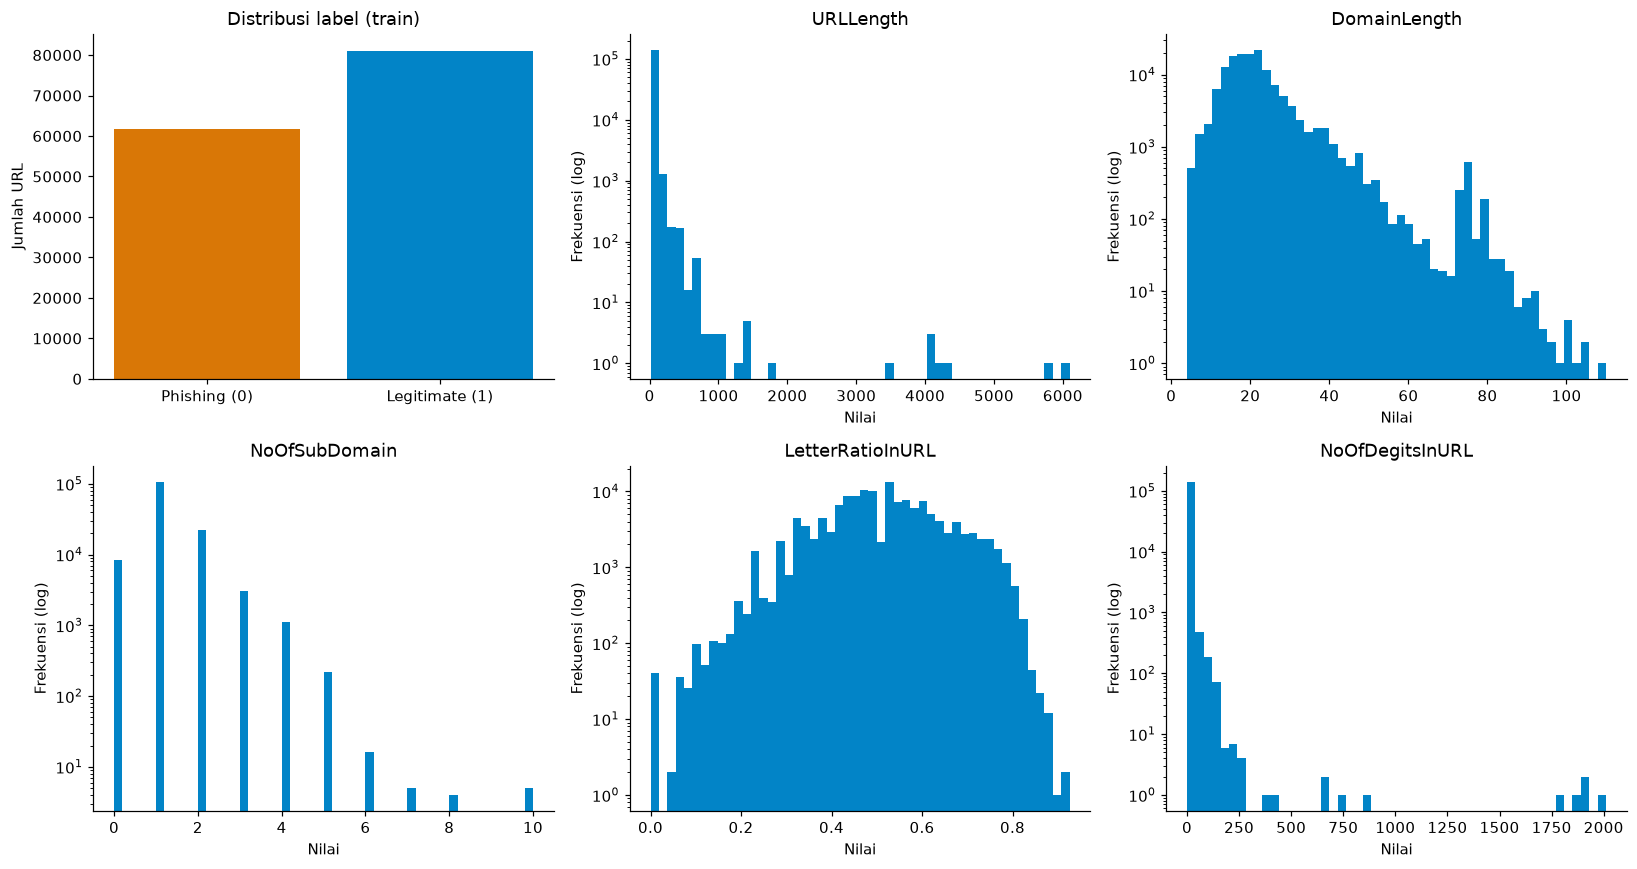

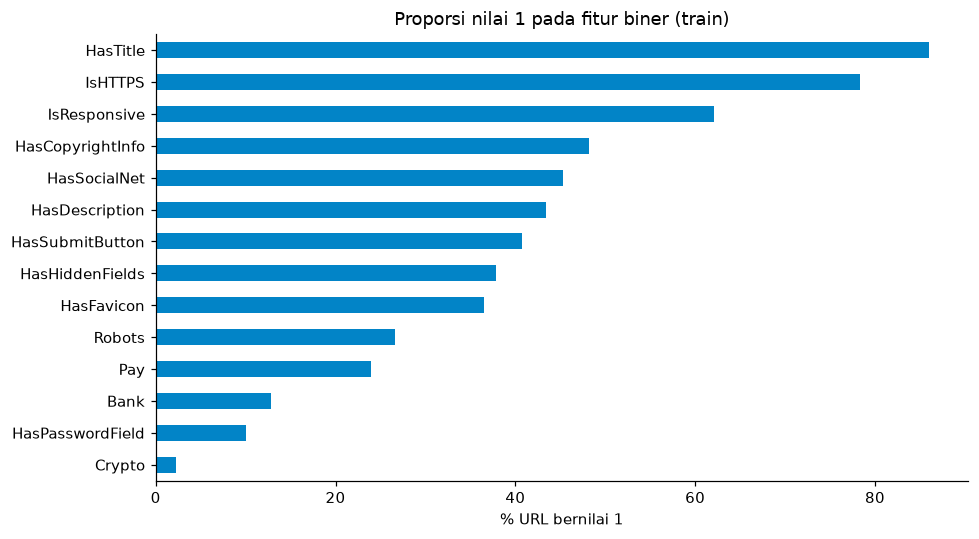

In [7]:
class DataExplorer:
    numeric = ["URLLength", "DomainLength", "NoOfSubDomain", "NoOfLettersInURL", "LetterRatioInURL",
               "NoOfDegitsInURL", "LineOfCode", "NoOfExternalRef"]
    binary = ["IsHTTPS", "HasTitle", "HasFavicon", "Robots", "IsResponsive", "HasDescription", "HasSocialNet",
              "HasSubmitButton", "HasHiddenFields", "HasPasswordField", "HasCopyrightInfo", "Bank", "Pay", "Crypto"]

    def __init__(self, X, y):
        self.X, self.y = X.reset_index(drop=True), np.asarray(y)
        self.label = pd.Series(self.y).map(LABEL_NAMES)
        self.order = [LABEL_NAMES[PHISHING], LABEL_NAMES[1 - PHISHING]]
        self.colors = [COLOR_PHISHING, COLOR_LEGIT]

    def univariate(self):
        counts = self.label.value_counts().reindex(self.order)
        display(pd.DataFrame({"Jumlah": counts, "Persen": 100 * counts / counts.sum()}).round(2))
        stats = self.X[self.numeric].describe().T
        stats["skewness"] = self.X[self.numeric].skew()
        display(stats.round(4))
        share = (100 * self.X[self.binary].mean()).sort_values(ascending=False)
        display(share.round(2).to_frame("% bernilai 1"))
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        axes[0, 0].bar(self.order, counts.values, color=self.colors)
        axes[0, 0].set(title="Distribusi label (train)", ylabel="Jumlah URL")
        for ax, feature in zip(axes.flat[1:], ["URLLength", "DomainLength", "NoOfSubDomain",
                                               "LetterRatioInURL", "NoOfDegitsInURL"]):
            ax.hist(self.X[feature], bins=50, color=COLOR_LEGIT)
            ax.set(title=feature, xlabel="Nilai", ylabel="Frekuensi (log)", yscale="log")
        plt.tight_layout(); plt.show()
        share.sort_values().plot.barh(figsize=(9, 5), color=COLOR_LEGIT)
        plt.title("Proporsi nilai 1 pada fitur biner (train)"); plt.xlabel("% URL bernilai 1")
        plt.tight_layout(); plt.show()

    def bivariate(self):
        grouped = self.X[self.numeric].groupby(self.label)
        center = pd.concat({"Median": grouped.median().T[self.order], "Rata-rata": grouped.mean().T[self.order]}, axis=1)
        display(center.round(4))
        rates = (100 * self.X[self.binary].groupby(self.label).mean().T)[self.order]
        rates["Selisih (poin %)"] = rates[self.order[1]] - rates[self.order[0]]
        rates = rates.sort_values("Selisih (poin %)", key=np.abs, ascending=False)
        display(rates.round(2))
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for ax, feature in zip(axes.flat, ["URLLength", "DomainLength", "NoOfDegitsInURL",
                                           "LetterRatioInURL", "LineOfCode", "NoOfExternalRef"]):
            ax.boxplot([self.X.loc[self.y == c, feature] for c in (PHISHING, 1 - PHISHING)],
                       tick_labels=self.order, showfliers=False)
            ax.set(title=f"{feature} menurut label", ylabel=feature)
        plt.tight_layout(); plt.show()
        rates[self.order].iloc[::-1].plot.barh(figsize=(10, 6), color=self.colors)
        plt.title("Proporsi fitur biner bernilai 1 menurut label (train)"); plt.xlabel("% URL bernilai 1")
        plt.tight_layout(); plt.show()

    def multivariate(self):
        corr_label = self.X.corrwith(pd.Series(self.y, dtype="float64")).dropna()
        top = corr_label.abs().sort_values(ascending=False).head(12).index
        corr = self.X[top].assign(label=self.y).corr()
        display(corr_label.loc[top].round(4).to_frame("Korelasi dengan label"))
        fig, ax = plt.subplots(figsize=(11, 9))
        im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
        ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
        ax.set_yticks(range(len(corr)), corr.columns)
        for i in range(len(corr)):
            for j in range(len(corr)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
        ax.set_title("Korelasi Pearson 12 fitur dengan |korelasi| terbesar terhadap label (train)")
        fig.colorbar(im, ax=ax, label="Korelasi Pearson")
        plt.tight_layout(); plt.show()
        full = self.X.corr().abs()
        upper = full.where(np.triu(np.ones(full.shape, dtype=bool), k=1))
        pairs = upper.stack(future_stack=True).dropna()
        pairs = pairs[pairs >= 0.9].sort_values(ascending=False)
        pairs.index.names = ["Fitur A", "Fitur B"]
        display(pairs.round(4).to_frame("|r| >= 0,9"))
        sample = self.X.assign(label=self.y).sample(min(4000, len(self.X)), random_state=cfg.seed)
        fig, ax = plt.subplots(figsize=(10, 5))
        for c, color in [(PHISHING, COLOR_PHISHING), (1 - PHISHING, COLOR_LEGIT)]:
            subset = sample[sample.label == c]
            ax.scatter(subset["URLLength"], subset["LetterRatioInURL"], s=10, alpha=0.4,
                       color=color, label=LABEL_NAMES[c])
        ax.set(xscale="log", xlabel="URLLength (skala log)", ylabel="LetterRatioInURL",
               title="URLLength dan LetterRatioInURL menurut label — sampel 4.000 URL train")
        ax.legend(); plt.tight_layout(); plt.show()

eda = DataExplorer(X.iloc[train_idx], y[train_idx])
eda.univariate()

### Langkah 1.3: Analisis bivariate
Setiap fitur dipasangkan dengan label. Sel ini menampilkan median dan rata-rata fitur numerik per kelas, boxplot, dan proporsi fitur biner bernilai 1 per kelas. Pencilan tidak digambar pada boxplot, tetapi tetap ada di data.

Median                   Rata-rata               
                 Phishing (0) Legitimate (1) Phishing (0) Legitimate (1)
URLLength              34.000         26.000    46.650600      26.228201
DomainLength           21.000         19.000    24.309900      19.228201
NoOfSubDomain           1.000          1.000     1.179400       1.164600
NoOfLettersInURL       20.000         13.000    28.761999      12.928900
LetterRatioInURL        0.571          0.481     0.566700       0.476600
NoOfDegitsInURL         0.000          0.000     4.541200       0.050100
LineOfCode             11.000       1100.000    65.204102    1940.943359
NoOfExternalRef         0.000         45.000     1.128500      84.672897

,Phishing (0),Legitimate (1),Selisih (poin %)
HasSocialNet,0.420000,79.459999,79.050003
HasCopyrightInfo,5.320000,80.720001,75.400002
HasDescription,3.780000,73.459999,69.680000
HasSubmitButton,7.720000,65.910004,58.189999
IsResponsive,31.389999,85.470001,54.080002
IsHTTPS,49.790001,100.000000,50.209999
HasHiddenFields,9.790000,59.200001,49.410000
HasFavicon,9.880000,56.799999,46.919998
Robots,6.820000,41.619999,34.799999
HasTitle,67.839996,99.879997,32.040001


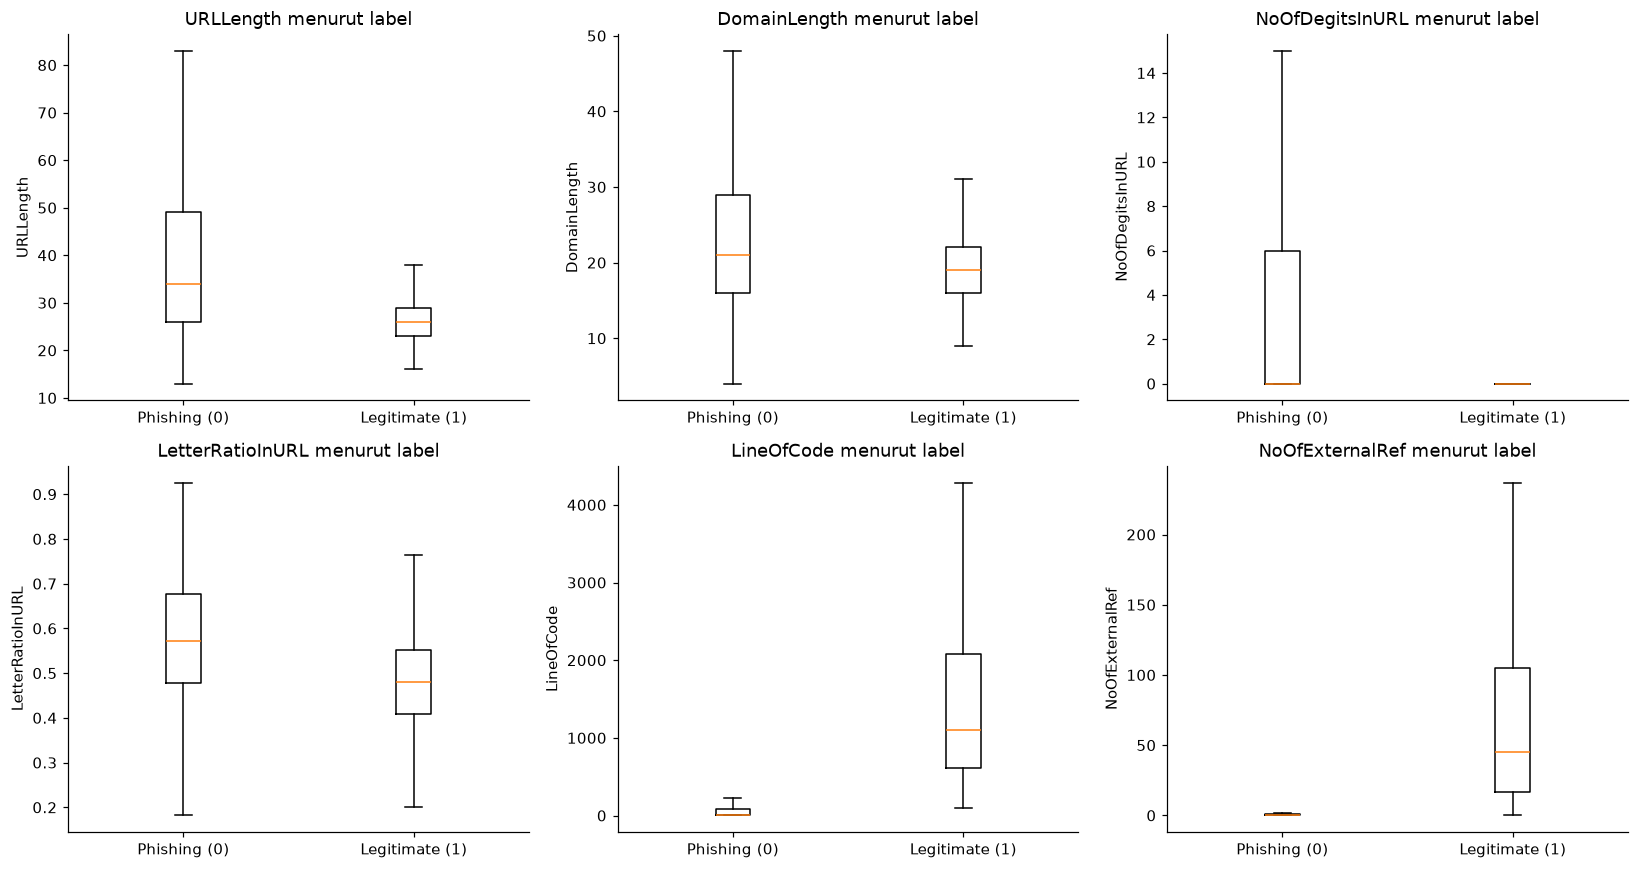

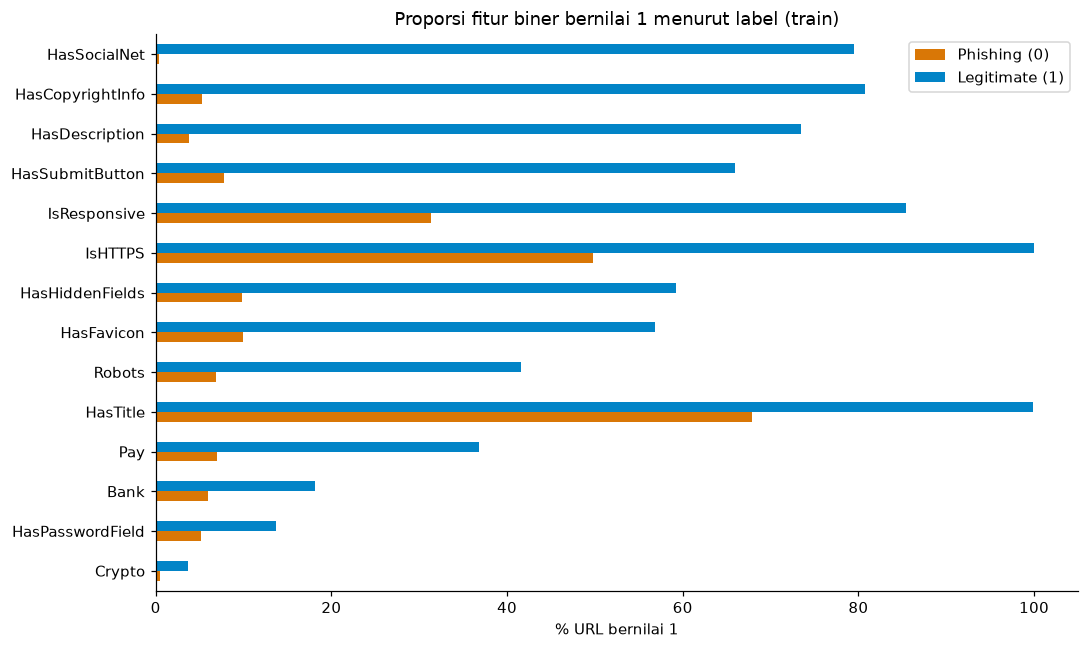

In [8]:
eda.bivariate()

### Langkah 1.4: Analisis multivariate
Beberapa variabel dilihat bersamaan. Heatmap korelasi Pearson memuat dua belas fitur yang paling berkorelasi dengan label. Pasangan fitur dengan |r| ≥ 0,9 didaftarkan sebagai indikasi redundansi, dan scatter plot dua fitur URL diberi warna menurut label.

,Korelasi dengan label
URLSimilarityIndex,0.8590
HasSocialNet,0.7865
HasCopyrightInfo,0.7475
HasDescription,0.6964
IsHTTPS,0.6035
DomainTitleMatchScore,0.5867
HasSubmitButton,0.5866
IsResponsive,0.5522
URLTitleMatchScore,0.5396
SpacialCharRatioInURL,-0.5343


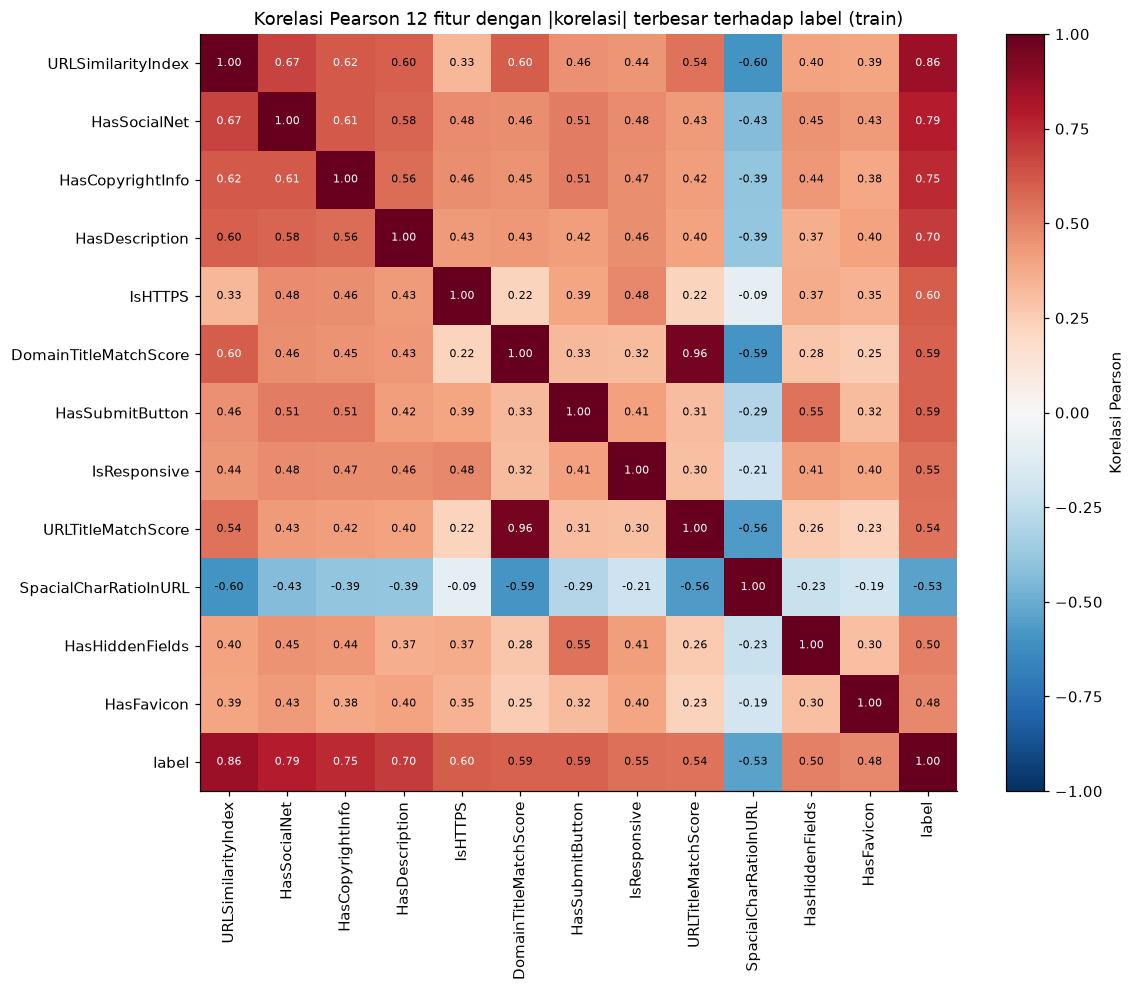

,,"|r| >= 0,9"
Fitur A,Fitur B,
DomainTitleMatchScore,URLTitleMatchScore,0.9595
URLLength,NoOfLettersInURL,0.9509


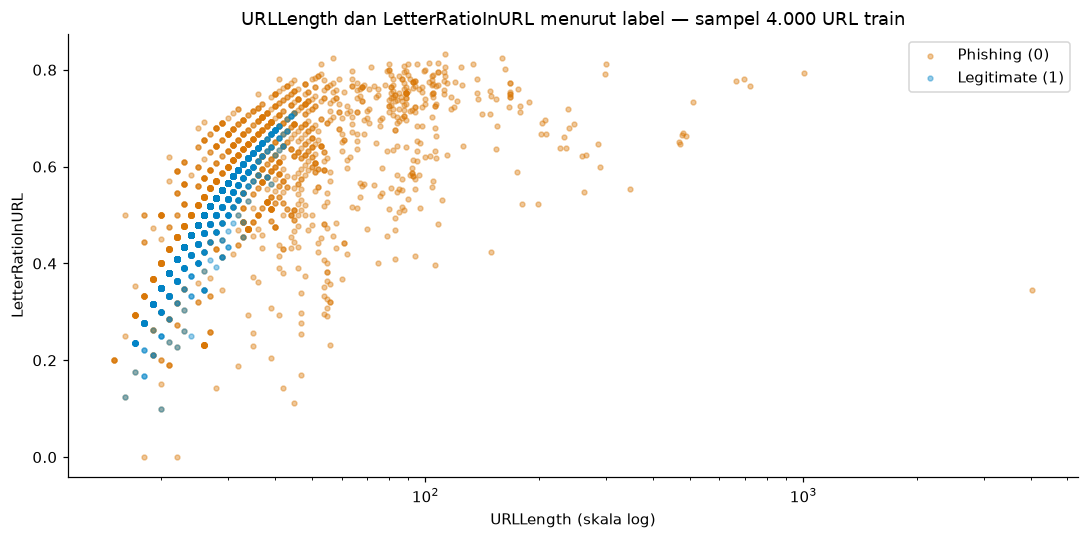

In [9]:
eda.multivariate()

## Bagian 2: Feature selection dengan perbandingan ambang AUC
### Langkah 2.1: Hitung AUC satu fitur pada train
Setiap fitur dipakai sendiri sebagai skor pada train asli, lalu ROC-AUC-nya dihitung. AUC dinyatakan dua arah, max(AUC, 1 − AUC). Nilai 0,5 berarti fitur tidak membedakan kelas, sedangkan 1,0 berarti satu fitur saja sudah memisahkan kelas dengan sempurna. Fitur dengan AUC sangat tinggi berisiko mendominasi model. Tiga skor referensi dataset (URLSimilarityIndex, TLDLegitimateProb, URLCharProb) selalu dikeluarkan karena ketiganya skor turunan yang dihitung dari pembanding URL legitimate dan tidak berasal langsung dari atribut URL atau halaman.

AUC tinggi menunjukkan daya pisah univariat yang tinggi dan tidak membuktikan kebocoran label. Penghapusan ini merupakan pilihan eksperimen untuk membatasi dominasi, sehingga perlu dibandingkan dengan seleksi prediktif RFE.

In [10]:
class FeatureSelector:
    reference_features = {"URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb"}

    def fit(self, X, y):
        rows = []
        for feature in X:
            values = X[feature]
            auc = np.nan
            if values.notna().any():
                raw_auc = roc_auc_score(y, values.fillna(values.median()))
                auc = max(raw_auc, 1 - raw_auc)
            rows.append({"feature": feature, "single_feature_train_auc": auc,
                         "kosong": bool(values.isna().all()),
                         "skor_referensi": feature in self.reference_features})
        self.audit_ = pd.DataFrame(rows)
        return self

    def select(self, threshold):
        # threshold=None berarti tanpa seleksi (hanya fitur kosong yang dibuang).
        audit = self.audit_
        keep = ~audit["kosong"]
        if threshold is not None:
            keep &= ~audit["skor_referensi"] & (audit["single_feature_train_auc"] <= threshold)
        return audit.loc[keep, "feature"].tolist()

    def status(self, threshold):
        audit = self.audit_.copy()
        audit["status"] = np.select(
            [audit["kosong"], audit["skor_referensi"], audit["single_feature_train_auc"] > threshold],
            ["Kosong pada train", "Skor referensi", "AUC > ambang"], default="Dipakai")
        return audit[["feature", "single_feature_train_auc", "status"]]

selector = FeatureSelector().fit(X.iloc[train_idx], y[train_idx])
display(selector.audit_.sort_values("single_feature_train_auc", ascending=False)
        .reset_index(drop=True).round(6))

,feature,single_feature_train_auc,kosong,skor_referensi
0,URLSimilarityIndex,0.996042,False,True
1,LineOfCode,0.990197,False,False
2,NoOfExternalRef,0.987826,False,False
3,NoOfImage,0.976709,False,False
4,NoOfSelfRef,0.973844,False,False
5,NoOfJS,0.970272,False,False
6,NoOfCSS,0.958881,False,False
7,HasSocialNet,0.895238,False,False
8,HasCopyrightInfo,0.877007,False,False
9,HasDescription,0.848382,False,False


### Langkah 2.2: Bandingkan beberapa ambang AUC
Fitur dengan AUC satu fitur lebih dari ambang dihapus. Kandidat ambangnya 0,70; 0,75; 0,80; 0,85; 0,90; 0,95; dan 1,00. Pada ambang 1,00 tidak ada batas AUC, dan hanya skor referensi yang dikeluarkan. Baris "Tanpa seleksi" memakai seluruh 50 fitur sebagai pembanding.

Untuk setiap ambang, imputasi median dan StandardScaler di-fit ulang pada train. XGBoost dengan konfigurasi Bagian 3 dilatih pada train asli, lalu dinilai pada validation. Dominasi fitur diukur dengan pangsa gain fitur teratas, yaitu gain rata-rata satu fitur teratas yang dinormalisasi terhadap jumlah gain rata-rata semua fitur (importance_type="gain"). Nilai ini berbeda dari proporsi total_gain.

Aturan pemilihan ditetapkan sebelum melihat hasil:
1. Ambang harus memenuhi target bisnis pada validation: recall phishing ≥ 95%, precision phishing ≥ 95%, dan FPR ≤ 5%.
2. Dari ambang yang lolos, pilih yang pangsa gain fitur teratasnya paling kecil, artinya fitur teratasnya paling tidak dominan. Jika sama, pilih ambang yang lebih kecil.

,Ambang AUC,Jumlah fitur,AUC satu fitur maks,Fitur paling dominan,Pangsa gain teratas,Pangsa gain 3 teratas,Accuracy,Recall phishing,Precision phishing,FPR,Macro-F1,Logloss,Memenuhi target
0,0.70,20,0.674012,HasTitle,0.605751,0.769966,0.876622,0.791873,0.898211,0.063453,0.870309,0.263903,False
1,0.75,29,0.747049,HasTitle,0.360933,0.743257,0.997126,0.995163,0.997891,0.001487,0.997037,0.010324,True
2,0.80,35,0.792573,IsHTTPS,0.438757,0.776984,0.998650,0.997319,0.999421,0.000409,0.998609,0.006870,True
3,0.85,39,0.848382,HasDescription,0.543923,0.825821,0.999216,0.998738,0.999369,0.000446,0.999192,0.003191,True
4,0.90,41,0.895238,HasSocialNet,0.799682,0.931442,0.999434,0.999369,0.999264,0.000520,0.999417,0.002006,True
5,0.95,41,0.895238,HasSocialNet,0.799682,0.931442,0.999434,0.999369,0.999264,0.000520,0.999417,0.002006,True
6,1.00,47,0.990197,NoOfExternalRef,0.855102,0.923970,0.999782,0.999579,0.999895,0.000074,0.999776,0.000998,True
7,Tanpa seleksi,50,0.996042,URLSimilarityIndex,0.983231,0.999010,1.000000,1.000000,1.000000,0.000000,1.000000,0.000012,True


Ambang terpilih: 0.75 | 29 fitur | fitur teratas HasTitle dengan pangsa gain 36.09%


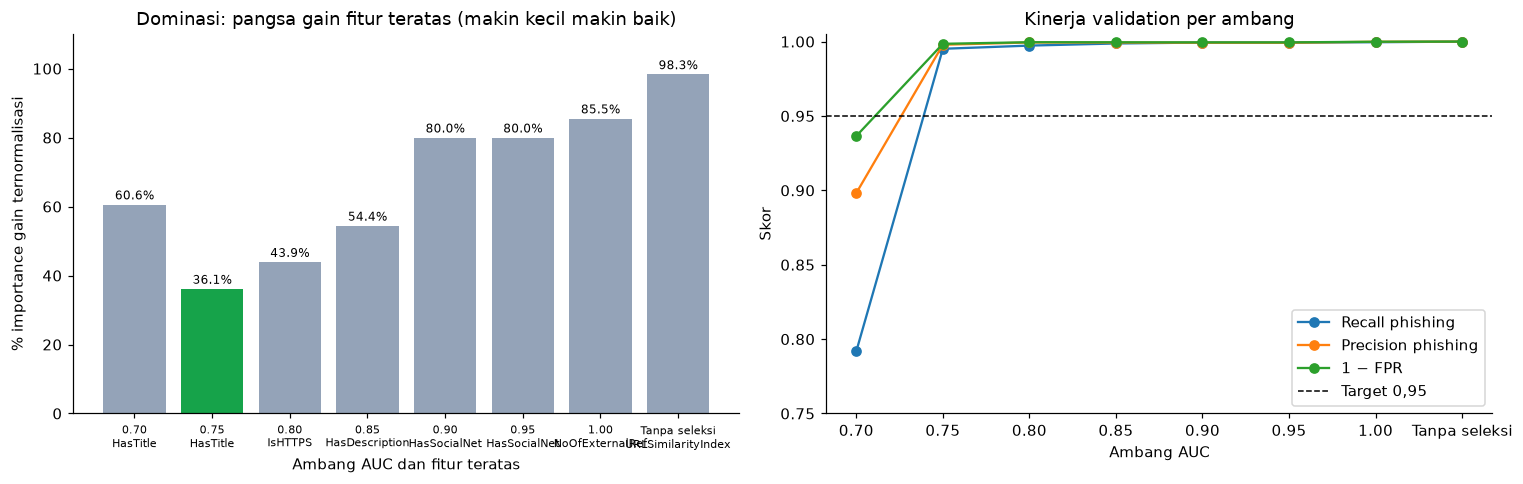

In [11]:
class Preprocessor:
    # Imputasi median dan StandardScaler yang hanya di-fit pada train.
    def fit(self, frame):
        self.imputer = SimpleImputer(strategy="median").fit(frame)
        self.scaler = StandardScaler().fit(self.imputer.transform(frame))
        return self

    def transform(self, frame):
        return self.scaler.transform(self.imputer.transform(frame)).astype("float32")


def prepare(features):
    prep = Preprocessor().fit(X[features].iloc[train_idx])
    return prep, {name: prep.transform(X[features].iloc[idx]) for name, idx in parts.items()}


auc_by_feature = selector.audit_.set_index("feature")["single_feature_train_auc"]
threshold_rows = []
for threshold in [*cfg.auc_thresholds, None]:
    features = selector.select(threshold)
    _, set_matrices = prepare(features)
    model = make_xgb().fit(set_matrices["Train"], y[train_idx])
    gain = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
    row = {"Ambang AUC": "Tanpa seleksi" if threshold is None else f"{threshold:.2f}",
           "Jumlah fitur": len(features), "AUC satu fitur maks": auc_by_feature[features].max(),
           "Fitur paling dominan": gain.index[0], "Pangsa gain teratas": gain.iloc[0],
           "Pangsa gain 3 teratas": gain.iloc[:3].sum(),
           **phishing_metrics(y[valid_idx], phishing_probability(model, set_matrices["Validation"]))}
    row["Memenuhi target"] = meets_target(row)
    threshold_rows.append(row)

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table[["Ambang AUC", "Jumlah fitur", "AUC satu fitur maks", "Fitur paling dominan",
                         "Pangsa gain teratas", "Pangsa gain 3 teratas", "Accuracy", "Recall phishing",
                         "Precision phishing", "FPR", "Macro-F1", "Logloss", "Memenuhi target"]].round(6))

candidates = threshold_table[(threshold_table["Ambang AUC"] != "Tanpa seleksi") & threshold_table["Memenuhi target"]]
if candidates.empty:
    raise ValueError("Tidak ada ambang yang memenuhi target pada validation.")
chosen = candidates.sort_values(["Pangsa gain teratas", "Ambang AUC"]).iloc[0]
best_threshold = float(chosen["Ambang AUC"])
print(f"Ambang terpilih: {best_threshold:.2f} | {chosen['Jumlah fitur']} fitur | fitur teratas "
      f"{chosen['Fitur paling dominan']} dengan pangsa gain {100 * chosen['Pangsa gain teratas']:.2f}%")

labels_x = threshold_table["Ambang AUC"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bar_colors = ["#16a34a" if a == chosen["Ambang AUC"] else "#94a3b8" for a in labels_x]
positions = np.arange(len(labels_x))
axes[0].bar(positions, 100 * threshold_table["Pangsa gain teratas"], color=bar_colors)
for i, share in enumerate(threshold_table["Pangsa gain teratas"]):
    axes[0].text(i, 100 * share + 1.5, f"{100 * share:.1f}%", ha="center", fontsize=8)
axes[0].set_xticks(positions, [f"{a}\n{n}" for a, n in zip(labels_x, threshold_table["Fitur paling dominan"])],
                   fontsize=7)
axes[0].set(title="Dominasi: pangsa gain fitur teratas (makin kecil makin baik)", xlabel="Ambang AUC dan fitur teratas",
            ylabel="% importance gain ternormalisasi", ylim=(0, 110))
axes[1].plot(labels_x, threshold_table["Recall phishing"], marker="o", label="Recall phishing")
axes[1].plot(labels_x, threshold_table["Precision phishing"], marker="o", label="Precision phishing")
axes[1].plot(labels_x, 1 - threshold_table["FPR"], marker="o", label="1 − FPR")
axes[1].axhline(0.95, color="black", linestyle="--", linewidth=1, label="Target 0,95")
axes[1].set(title="Kinerja validation per ambang", xlabel="Ambang AUC", ylabel="Skor", ylim=(0.75, 1.005))
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
if best_threshold != 0.75:
    raise RuntimeError(f"Ambang hasil validasi {best_threshold} berbeda dari laporan (0.75).")


### Langkah 2.3: Terapkan ambang terpilih dan siapkan matriks
Fitur dengan AUC satu fitur di atas ambang terpilih dihapus. Imputasi dan scaling di-fit pada train, lalu diterapkan ke validation dan test. Bagian 3 sampai 5 memakai train asli tanpa SMOTE, dan SMOTE baru diterapkan serta dibandingkan pada Bagian 6.

,feature,single_feature_train_auc,status
0,URLSimilarityIndex,0.996042,Skor referensi
1,LineOfCode,0.990197,AUC > ambang
2,NoOfExternalRef,0.987826,AUC > ambang
3,NoOfImage,0.976709,AUC > ambang
4,NoOfSelfRef,0.973844,AUC > ambang
5,NoOfJS,0.970272,AUC > ambang
6,NoOfCSS,0.958881,AUC > ambang
7,HasSocialNet,0.895238,AUC > ambang
8,HasCopyrightInfo,0.877007,AUC > ambang
9,HasDescription,0.848382,AUC > ambang


,Jumlah fitur
status,
Dipakai,29
AUC > ambang,18
Skor referensi,3


Fitur terpilih (29 dari 50): URLLength, DomainLength, IsDomainIP, CharContinuationRate, TLDLength, NoOfSubDomain, HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio, NoOfLettersInURL, LetterRatioInURL, NoOfDegitsInURL, DegitRatioInURL, NoOfEqualsInURL, NoOfQMarkInURL, NoOfAmpersandInURL, HasTitle, HasFavicon, Robots, NoOfURLRedirect, NoOfSelfRedirect, NoOfPopup, HasExternalFormSubmit, HasHiddenFields, HasPasswordField, Bank, Pay, Crypto, NoOfEmptyRef


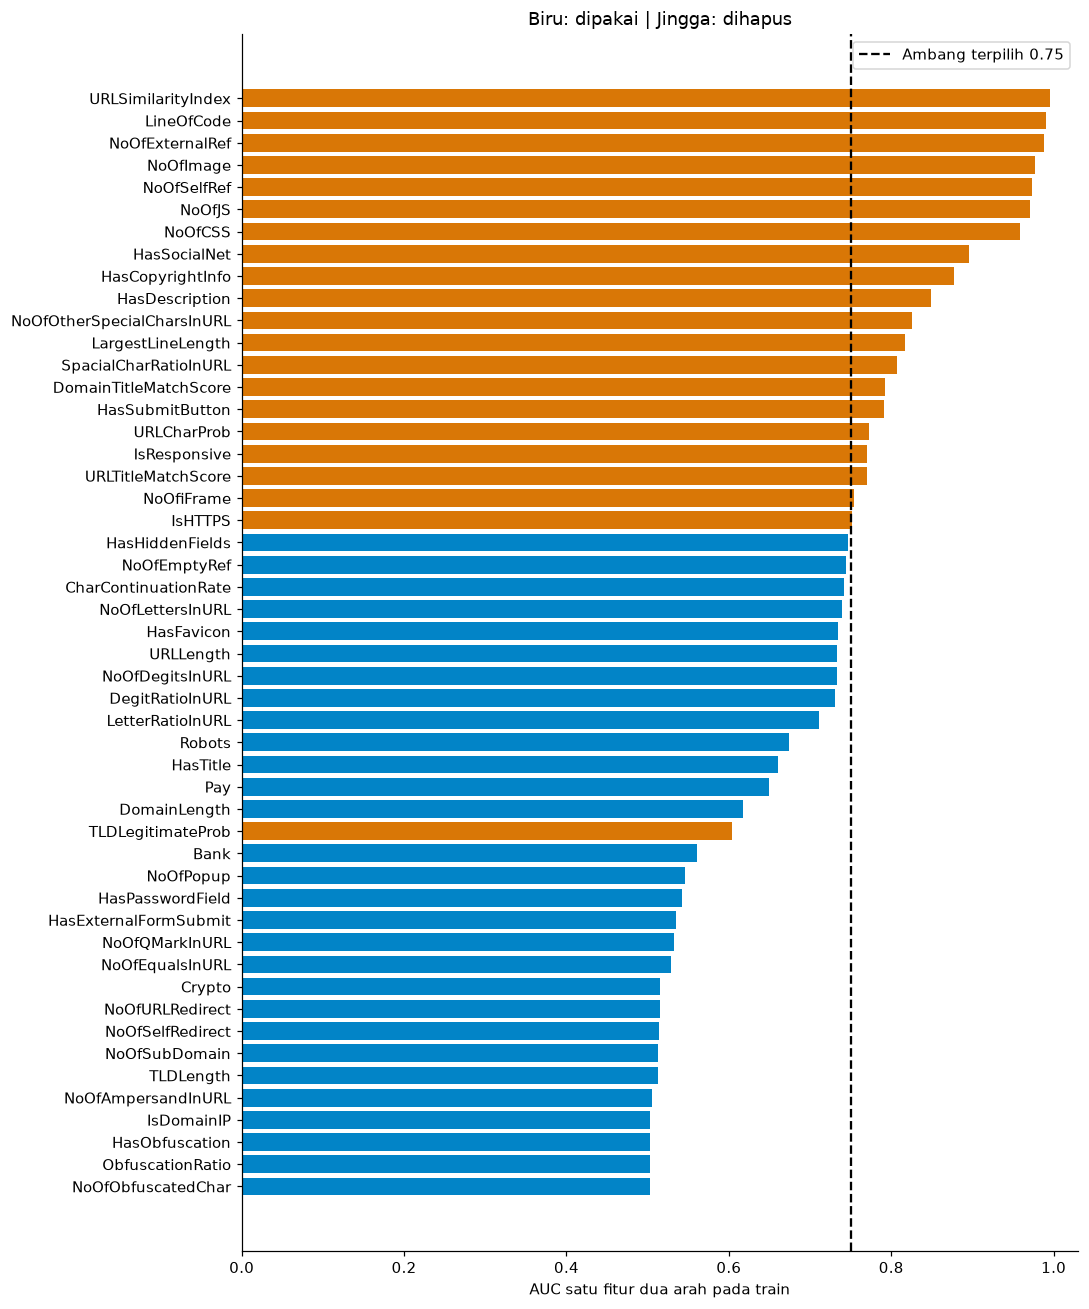

{'Train': (142748, 29), 'Validation': (45924, 29), 'Test': (46314, 29)}


In [12]:
features = selector.select(best_threshold)
feature_status = selector.status(best_threshold)
display(feature_status.sort_values("single_feature_train_auc", ascending=False).reset_index(drop=True).round(6))
display(feature_status["status"].value_counts().to_frame("Jumlah fitur"))
print(f"Fitur terpilih ({len(features)} dari {X.shape[1]}):", ", ".join(features))

frame = feature_status.sort_values("single_feature_train_auc")
fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(frame.feature, frame.single_feature_train_auc,
        color=np.where(frame.status == "Dipakai", COLOR_LEGIT, COLOR_PHISHING))
ax.axvline(best_threshold, color="black", linestyle="--", label=f"Ambang terpilih {best_threshold:.2f}")
ax.set(xlim=(0, 1.03), xlabel="AUC satu fitur dua arah pada train", title="Biru: dipakai | Jingga: dihapus")
ax.legend(); plt.tight_layout(); plt.show()

preprocessor, matrices = prepare(features)
labels = {name: y[idx] for name, idx in parts.items()}
print({name: matrix.shape for name, matrix in matrices.items()})
REFERENCE_AUC_FEATURES = ['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'HasTitle', 'HasFavicon', 'Robots', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'NoOfPopup', 'HasExternalFormSubmit', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'NoOfEmptyRef']
assert features == REFERENCE_AUC_FEATURES, "Daftar/urutan fitur berbeda dari 29 fitur laporan."


## Bagian 3: XGBoost dengan library (plugin)
### Langkah 3.1: Siapkan kelas eksperimen
Metrik dihitung pada train, validation, dan test dengan phishing sebagai kelas positif. Confusion matrix dan kurva ROC ditampilkan untuk test.

In [13]:
class ModelExperiment:
    def __init__(self, name, model):
        self.name, self.model = name, model

    def fit(self, X_fit, y_fit, **kwargs):
        start = perf_counter()
        self.model.fit(X_fit, y_fit, **kwargs)
        self.seconds_ = perf_counter() - start
        print(f"{self.name}: {self.seconds_:.2f} detik; {len(y_fit):,} baris latih")
        return self

    def evaluate(self, matrices, labels, show=True):
        rows, self.proba_ = [], {}
        for split, matrix in matrices.items():
            p = phishing_probability(self.model, matrix)
            self.proba_[split] = p
            rows.append({"Model": self.name, "Split": split, "Baris": len(labels[split]),
                         **phishing_metrics(labels[split], p)})
        self.metrics_ = pd.DataFrame(rows)
        if show:
            display(self.metrics_.round(6))
            actual = (labels["Test"] == PHISHING).astype(int)
            pred = (self.proba_["Test"] >= 0.5).astype(int)
            display(pd.DataFrame(classification_report(actual, pred, target_names=["Legitimate", "Phishing"],
                                                       output_dict=True, zero_division=0)).T.round(6))
            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            ConfusionMatrixDisplay.from_predictions(actual, pred, labels=[0, 1],
                display_labels=["Legitimate", "Phishing"], ax=axes[0], cmap="Blues", colorbar=False,
                values_format="d")
            RocCurveDisplay.from_predictions(actual, self.proba_["Test"], ax=axes[1], name=self.name)
            axes[0].set_title(f"Confusion matrix test — {self.name}")
            axes[1].set_title("ROC test (phishing positif)")
            plt.tight_layout(); plt.show()
        return self.metrics_

### Langkah 3.2: Pilih learning rate dengan validation
Konfigurasi awal proyek memakai learning rate 0,005. Jumlah pohon ditetapkan 300 agar implementasi NumPy pada Bagian 4 dapat dilatih dengan jumlah pohon yang sama. Kandidat 0,005; 0,05; 0,1; 0,3; dan 0,5 dibandingkan, lalu learning rate dengan logloss validation terendah pada pohon ke-300 dipilih. Test tidak dipakai.

,Learning rate,Logloss train (pohon 300),Logloss validation (pohon 300),Pohon dengan logloss validation terendah,Logloss validation terendah,Accuracy,Recall phishing,Precision phishing,FPR
0,0.005,0.203491,0.206305,300,0.206305,0.959956,0.976974,0.929897,0.052078
1,0.050,0.013409,0.018237,300,0.018237,0.994730,0.991957,0.995305,0.003308
2,0.100,0.006800,0.012368,300,0.012368,0.996298,0.994217,0.996837,0.002230
3,0.300,0.003210,0.010324,210,0.010171,0.997126,0.995163,0.997891,0.001487
4,0.500,0.002619,0.011298,126,0.010626,0.997082,0.995058,0.997891,0.001487


Learning rate terpilih: 0.3


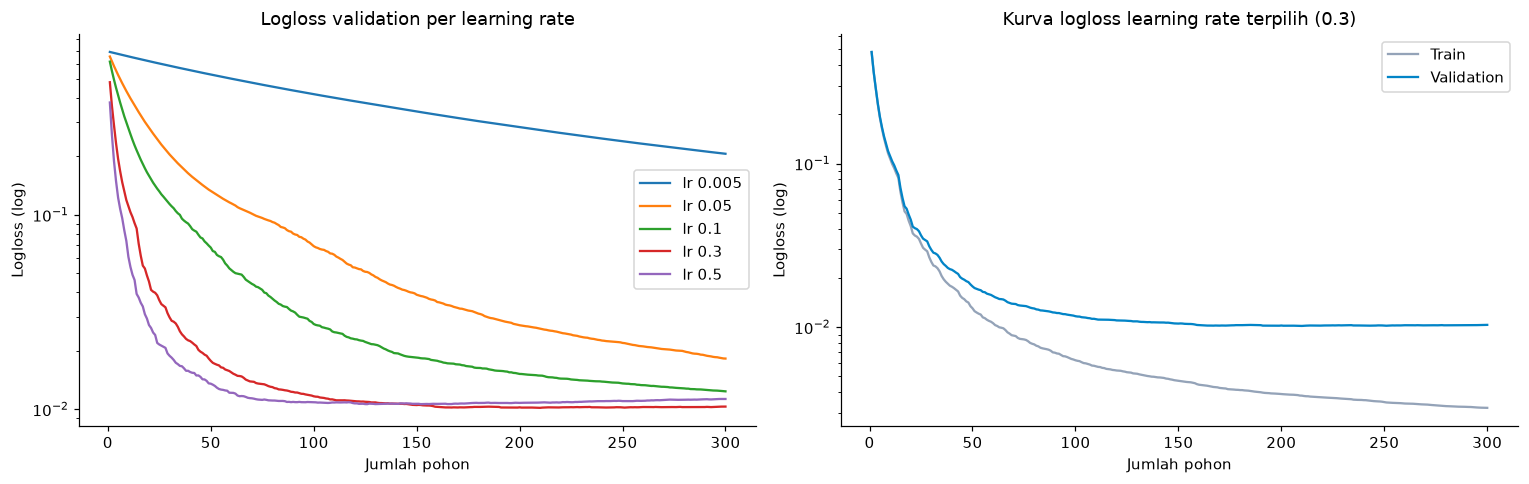

In [14]:
lr_rows, lr_curves = [], {}
for rate in cfg.learning_rates:
    candidate = make_xgb(learning_rate=rate).fit(
        matrices["Train"], labels["Train"], verbose=False,
        eval_set=[(matrices["Train"], labels["Train"]), (matrices["Validation"], labels["Validation"])])
    history = candidate.evals_result()
    train_curve = np.array(history["validation_0"]["logloss"])
    valid_curve = np.array(history["validation_1"]["logloss"])
    lr_curves[rate] = (train_curve, valid_curve)
    metrics = phishing_metrics(labels["Validation"], phishing_probability(candidate, matrices["Validation"]))
    lr_rows.append({"Learning rate": rate, "Logloss train (pohon 300)": train_curve[-1],
                    "Logloss validation (pohon 300)": valid_curve[-1],
                    "Pohon dengan logloss validation terendah": int(valid_curve.argmin() + 1),
                    "Logloss validation terendah": valid_curve.min(),
                    **{k: metrics[k] for k in ["Accuracy", "Recall phishing", "Precision phishing", "FPR"]}})
lr_table = pd.DataFrame(lr_rows)
display(lr_table.round(6))
best_lr = float(lr_table.loc[lr_table["Logloss validation (pohon 300)"].idxmin(), "Learning rate"])
print(f"Learning rate terpilih: {best_lr}")
if best_lr != 0.3:
    raise RuntimeError(f"Learning rate hasil validasi {best_lr} berbeda dari laporan (0.3).")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for rate, (train_curve, valid_curve) in lr_curves.items():
    axes[0].plot(np.arange(1, len(valid_curve) + 1), valid_curve, label=f"lr {rate}")
axes[0].set(title="Logloss validation per learning rate", xlabel="Jumlah pohon", ylabel="Logloss (log)", yscale="log")
axes[0].legend()
train_curve, valid_curve = lr_curves[best_lr]
axes[1].plot(np.arange(1, 301), train_curve, label="Train", color="#94a3b8")
axes[1].plot(np.arange(1, 301), valid_curve, label="Validation", color=COLOR_LEGIT)
axes[1].set(title=f"Kurva logloss learning rate terpilih ({best_lr})", xlabel="Jumlah pohon",
            ylabel="Logloss (log)", yscale="log")
axes[1].legend(); plt.tight_layout(); plt.show()


### Langkah 3.2b: Perbandingan AUC dua arah dan RFE
Desain ini dikunci sebelum test dilihat. AUC tetap menjadi jalur utama agar pembandingan library dan NumPy, baseline, serta SMOTE konsisten dengan rancangan awal. RFE menjadi eksperimen pembanding, dan hasil test tidak dipakai untuk memilih metode utama.

1. Kumpulan kandidatnya sama: fitur numerik tidak kosong, selain URLSimilarityIndex, TLDLegitimateProb, dan URLCharProb.
2. Jalur AUC mempertahankan fitur dengan max(AUC, 1-AUC) <= ambang terpilih. RFE menghapus fitur dengan importance terendah secara berulang memakai XGBoost dan `step=5` sampai tersisa k = jumlah fitur AUC. Prosedur ini memakai RFE biasa tanpa RFECV. Nilai k ditetapkan agar ukuran kedua subset sama, tanpa tuning lewat test.
3. RFE di-fit pada train saja. Kedua subset dinilai dengan XGBoost yang parameter dan learning rate-nya identik. Kontrol berisi semua fitur eligible tanpa pembatas AUC.
4. Hasil yang ditampilkan mencakup train, validation, test, ROC-AUC, AP, Macro-F1, logloss, waktu seleksi, dan gain teratas. Jika tujuannya murni prediksi, fitur dengan AUC tinggi tidak perlu dibuang, jadi dominasi yang menjadi tujuan filter AUC versi ini juga dibandingkan.


,Fitur,Ranking RFE,Dipilih RFE,Dipilih AUC
37,Bank,1,True,True
3,CharContinuationRate,1,True,True
12,DegitRatioInURL,1,True,True
1,DomainLength,1,True,True
22,DomainTitleMatchScore,1,True,False
40,HasCopyrightInfo,1,True,False
29,HasDescription,1,True,False
33,HasSocialNet,1,True,False
21,HasTitle,1,True,True
18,IsHTTPS,1,True,False


,Metode,Split,Jumlah fitur,Waktu seleksi (s),Waktu fit (s),Gain teratas,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP,Memenuhi target
0,AUC dua arah,Train,29,NaN,12.094078,0.360933,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561,True
1,AUC dua arah,Validation,29,NaN,12.094078,0.360933,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930,True
2,AUC dua arah,Test,29,NaN,12.094078,0.360933,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395,True
3,RFE,Train,29,44.142492,7.652042,0.855465,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000023,81102,0,0,61646,True
4,RFE,Validation,29,44.142492,7.652042,0.855465,0.999608,0.999895,0.999159,0.999527,0.999596,0.000074,0.999998,0.999997,0.001158,26900,2,16,19006,True
5,RFE,Test,29,44.142492,7.652042,0.855465,0.999935,0.999846,1.000000,0.999923,0.999934,0.000112,1.000000,1.000000,0.000292,26843,3,0,19468,True
6,Semua eligible,Train,47,NaN,10.397644,0.855102,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000023,81102,0,0,61646,True
7,Semua eligible,Validation,47,NaN,10.397644,0.855102,0.999782,0.999895,0.999579,0.999737,0.999776,0.000074,0.999998,0.999997,0.000998,26900,2,8,19014,True
8,Semua eligible,Test,47,NaN,10.397644,0.855102,0.999914,0.999795,1.000000,0.999897,0.999911,0.000149,1.000000,1.000000,0.000297,26842,4,0,19468,True


Fitur sama: 13/29; Jaccard = 0.2889
Hanya AUC: ['Crypto', 'HasExternalFormSubmit', 'HasFavicon', 'HasHiddenFields', 'HasObfuscation', 'HasPasswordField', 'IsDomainIP', 'NoOfAmpersandInURL', 'NoOfEqualsInURL', 'NoOfObfuscatedChar', 'NoOfQMarkInURL', 'NoOfSelfRedirect', 'NoOfURLRedirect', 'ObfuscationRatio', 'Pay', 'Robots']
Hanya RFE: ['DomainTitleMatchScore', 'HasCopyrightInfo', 'HasDescription', 'HasSocialNet', 'IsHTTPS', 'IsResponsive', 'LargestLineLength', 'LineOfCode', 'NoOfCSS', 'NoOfExternalRef', 'NoOfImage', 'NoOfJS', 'NoOfOtherSpecialCharsInURL', 'NoOfSelfRef', 'SpacialCharRatioInURL', 'URLTitleMatchScore']
Waktu seleksi RFE termasuk preprocessing: 44.14 detik
Waktu seleksi AUC tidak diukur terpisah; NaN bukan nol. Tuning ambang tidak termasuk waktu fit.


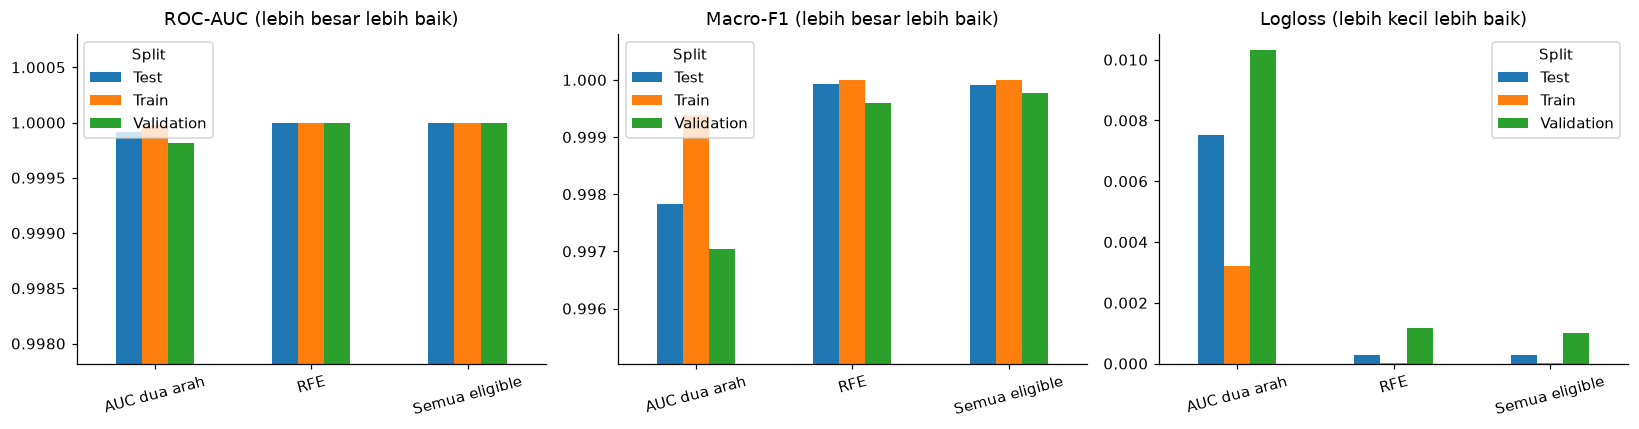

In [15]:
auc_features = list(features)
eligible = selector.audit_.loc[~selector.audit_["kosong"] & ~selector.audit_["skor_referensi"], "feature"].tolist()
k = len(auc_features)
assert set(auc_features) <= set(eligible)
t0 = perf_counter()
rfe_prep = Preprocessor().fit(X[eligible].iloc[train_idx])
rfe = RFE(estimator=make_xgb(learning_rate=best_lr), n_features_to_select=k, step=5,
          importance_getter="feature_importances_")
rfe.fit(rfe_prep.transform(X[eligible].iloc[train_idx]), labels["Train"])
rfe_seconds = perf_counter() - t0
rfe_features = np.asarray(eligible)[rfe.support_].tolist()
rfe_ranking = pd.DataFrame({"Fitur": eligible, "Ranking RFE": rfe.ranking_,
    "Dipilih RFE": rfe.support_, "Dipilih AUC": [f in auc_features for f in eligible]})
display(rfe_ranking.sort_values(["Ranking RFE", "Fitur"]))
assert len(rfe_features) == len(auc_features)
feature_sets = {"AUC dua arah": auc_features, "RFE": rfe_features, "Semua eligible": eligible}
fs_models, fs_rows = {}, []
for method, columns in feature_sets.items():
    prep, mm = prepare(columns)
    model = make_xgb(learning_rate=best_lr)
    start = perf_counter()
    model.fit(mm["Train"], labels["Train"])
    fit_seconds = perf_counter() - start
    fs_models[method] = (model, prep, columns)
    for split in parts:
        row = {"Metode": method, "Split": split, "Jumlah fitur": len(columns),
            "Waktu seleksi (s)": rfe_seconds if method == "RFE" else np.nan,
            "Waktu fit (s)": fit_seconds, "Gain teratas": float(model.feature_importances_.max()),
            **phishing_metrics(labels[split], phishing_probability(model, mm[split]))}
        row["Memenuhi target"] = meets_target(row)
        fs_rows.append(row)
fs_comparison = pd.DataFrame(fs_rows)
fs_comparison.to_csv(OUT / "perbandingan_seleksi_fitur.csv", index=False)
rfe_ranking.to_csv(OUT / "ranking_rfe.csv", index=False)
display(fs_comparison.round(6))
shared = set(auc_features) & set(rfe_features)
print(f"Fitur sama: {len(shared)}/{k}; Jaccard = {len(shared)/len(set(auc_features)|set(rfe_features)):.4f}")
print("Hanya AUC:", sorted(set(auc_features)-set(rfe_features)))
print("Hanya RFE:", sorted(set(rfe_features)-set(auc_features)))
print("Waktu seleksi RFE termasuk preprocessing:", round(rfe_seconds, 2), "detik")
print("Waktu seleksi AUC tidak diukur terpisah; NaN bukan nol. Tuning ambang tidak termasuk waktu fit.")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["ROC-AUC", "Macro-F1", "Logloss"]):
    fs_comparison.pivot(index="Metode", columns="Split", values=metric).plot.bar(ax=ax, rot=15)
    ax.set_title(metric + (" (lebih kecil lebih baik)" if metric == "Logloss" else " (lebih besar lebih baik)"))
    ax.set_xlabel("")
    if metric != "Logloss":
        low = float(fs_comparison[metric].min())
        ax.set_ylim(max(0, low - 0.002), 1.0008)
fig.tight_layout()
fig.savefig(OUT / "perbandingan_auc_rfe.png", dpi=180, bbox_inches="tight")
plt.show()


### Langkah 3.3: Latih XGBoost library
Parameter yang dipakai adalah 300 pohon, max_depth 6, learning rate terpilih, λ = 1, min_child_weight = 1, γ = 0, base_score = 0,5, `tree_method="exact"`, subsample = 1, colsample_bytree = 1, objective `binary:logistic`, dan seed 42. Model dilatih pada train asli tanpa SMOTE.

In [16]:
plugin = ModelExperiment("XGBoost library", make_xgb(learning_rate=best_lr))
plugin.fit(matrices["Train"], labels["Train"])
display(pd.Series(plugin.model.get_params()).loc[["n_estimators", "max_depth", "learning_rate", "reg_lambda",
    "min_child_weight", "gamma", "base_score", "subsample", "colsample_bytree", "tree_method", "objective"]
    ].to_frame("Nilai parameter"))

XGBoost library: 12.17 detik; 142,748 baris latih


,Nilai parameter
n_estimators,300
max_depth,6
learning_rate,0.3
reg_lambda,1.0
min_child_weight,1.0
gamma,0.0
base_score,0.5
subsample,1.0
colsample_bytree,1.0
tree_method,exact


### Langkah 3.4: Evaluasi dan feature importance

,Model,Split,Baris,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
0,XGBoost library,Train,142748,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
1,XGBoost library,Validation,45924,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
2,XGBoost library,Test,46314,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395


,precision,recall,f1-score,support
Legitimate,0.997286,0.999069,0.998176,26846.000000
Phishing,0.998713,0.996250,0.997480,19468.000000
accuracy,0.997884,0.997884,0.997884,0.997884
macro avg,0.997999,0.997660,0.997828,46314.000000
weighted avg,0.997885,0.997884,0.997884,46314.000000


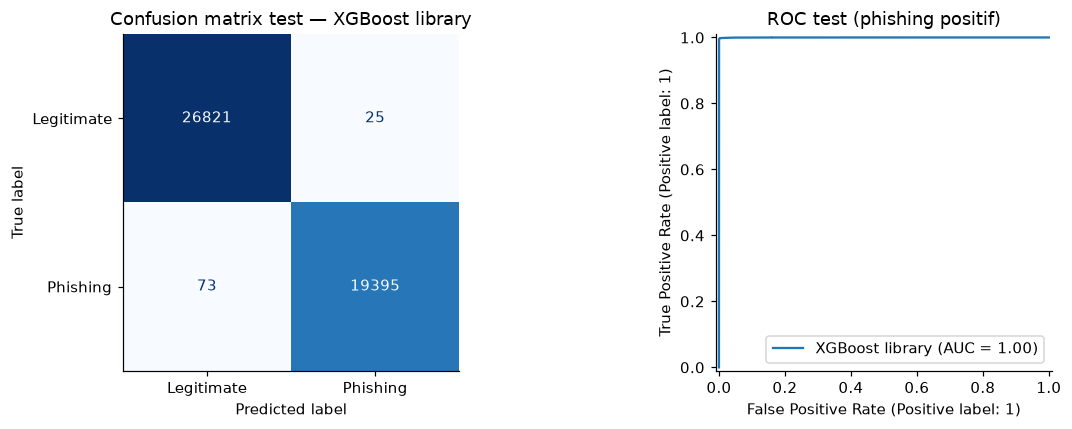

,% total gain
HasTitle,36.0933
NoOfDegitsInURL,21.4911
NoOfEmptyRef,16.7414
HasFavicon,5.5998
HasHiddenFields,5.4931
Pay,3.4439
Robots,1.7413
NoOfSelfRedirect,1.6421
NoOfSubDomain,1.5466
LetterRatioInURL,1.3386


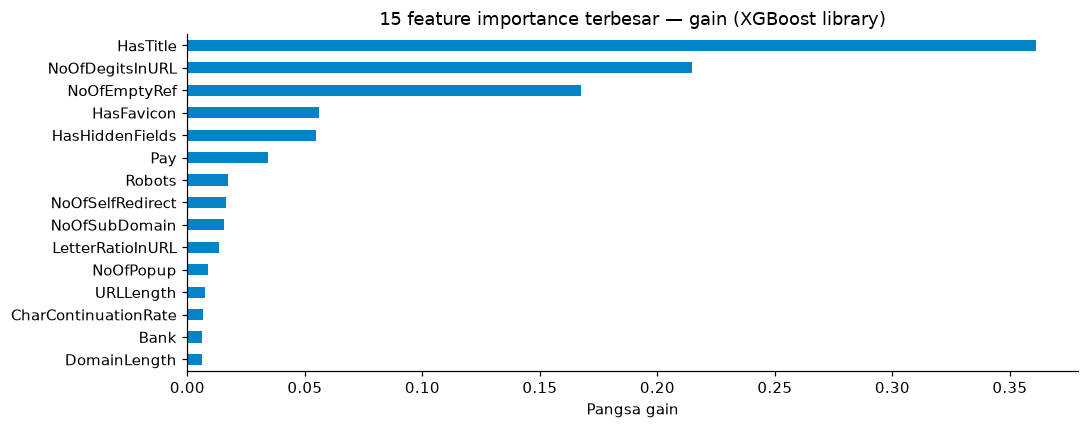

In [17]:
plugin_metrics = plugin.evaluate(matrices, labels)
importance = pd.Series(plugin.model.feature_importances_, index=features).sort_values(ascending=False)
display((100 * importance).round(4).to_frame("% total gain").head(15))
importance.head(15).iloc[::-1].plot.barh(color=COLOR_LEGIT, title="15 feature importance terbesar — gain (XGBoost library)")
plt.xlabel("Pangsa gain"); plt.tight_layout(); plt.show()

## Bagian 4: XGBoost dari nol (scratch) dengan NumPy
### Langkah 4.1: Implementasikan pohon dan boosting
Pembentukan pohon dan boosting ditulis sendiri dengan NumPy, dan library XGBoost tidak dipakai untuk melatih model ini. Setiap ronde menjalankan langkah berikut:

1. Hitung probabilitas $p = \sigma(F)$ dari margin $F$ (awal: $F_0 = \ln\frac{0{,}5}{1-0{,}5} = 0$).
2. Hitung gradien $g = p - y$ dan Hessian $h = p(1-p)$.
3. Cari split dengan gain terbesar: $\text{Gain} = \tfrac12\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{G^2}{H+\lambda}\right] - \gamma$.
4. Hitung bobot daun $w = -\frac{G}{H+\lambda}$, lalu perbarui margin $F \leftarrow F + \eta\,w$.

Implementasi ini memakai exact split, yaitu semua threshold di antara nilai yang berbeda, tanpa sampling. Konfigurasinya sama dengan library pada Bagian 3 sehingga hasilnya dapat dibandingkan angka per angka.

In [18]:
def sigmoid(margin):
    margin = np.asarray(margin, dtype=np.float32)
    # exp float32 SIMD NumPy dapat berbeda 1 ULP dari expf skalar; bulatkan exp presisi tinggi ke float32.
    exponential = np.exp(-np.clip(margin, -88, 88).astype(np.float64)).astype(np.float32)
    return (np.float32(1) / (np.float32(1) + exponential)).astype(np.float32)


@dataclass
class Node:
    weight: float
    gradient: float
    hessian: float
    rows: int
    feature: int = -1
    threshold: float = 0.0
    gain: float = 0.0
    left: object = None
    right: object = None


def tree_predict(node, matrix):
    output = np.empty(len(matrix), dtype=np.float32)

    def visit(current, indices):
        if current.feature < 0:
            output[indices] = current.weight
            return
        mask = matrix[indices, current.feature] < current.threshold
        visit(current.left, indices[mask])
        visit(current.right, indices[~mask])

    visit(node, np.arange(len(matrix)))
    return output


def count_leaves(node):
    return 1 if node.feature < 0 else count_leaves(node.left) + count_leaves(node.right)

In [19]:
class ScratchXGBoost:
    def __init__(self, n_estimators=300, max_depth=6, learning_rate=0.3,
                 reg_lambda=1.0, min_child_weight=1.0, base_score=0.5):
        if n_estimators < 1 or max_depth < 1 or learning_rate <= 0:
            raise ValueError("Jumlah pohon, kedalaman, dan learning rate harus positif")
        if reg_lambda <= 0 or min_child_weight < 0 or not 0 < base_score < 1:
            raise ValueError("Regularisasi atau base score tidak valid")
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = np.float32(learning_rate)
        self.reg_lambda = reg_lambda
        self.min_child_weight = min_child_weight
        self.base_score = base_score

    @staticmethod
    def _matrix(matrix):
        matrix = np.asarray(matrix, dtype=np.float32)
        if matrix.ndim != 2 or not matrix.shape[1] or not np.isfinite(matrix).all():
            raise ValueError("Dibutuhkan matriks 2D padat dan berhingga; lakukan imputasi lebih dulu")
        return matrix

    def fit(self, matrix, target, verbose=False):
        matrix = self._matrix(matrix)
        target = np.asarray(target, dtype=np.float32)
        if target.shape != (len(matrix),) or not len(target) or not np.isin(target, [0, 1]).all():
            raise ValueError("Dibutuhkan label biner, satu label per baris")
        self.n_features_in_ = matrix.shape[1]
        self.classes_ = np.array([0, 1])
        self.base_margin_ = np.float32(np.log(self.base_score / (1 - self.base_score)))
        margin = np.full(len(target), self.base_margin_, dtype=np.float32)
        self.trees_, self.loss_history_ = [], []
        # Urutan nilai fitur hanya bergantung pada X, sehingga cukup dihitung sekali.
        orders = [np.argsort(matrix[:, j], kind="stable") for j in range(matrix.shape[1])]
        for iteration in range(self.n_estimators):
            p = sigmoid(margin)                                   # 1. probabilitas
            g = p - target                                        # 2. gradien
            h = np.maximum(p * (1 - p), np.float32(1e-16))        #    Hessian
            tree = self._grow(matrix, g, h, orders, 0)            # 3. pohon dengan gain terbesar
            self.trees_.append(tree)
            margin += tree_predict(tree, matrix)                  # 4. F <- F + eta * w
            self.loss_history_.append(float(np.mean(np.logaddexp(0, margin) - target * margin)))
            if verbose and (iteration == 0 or (iteration + 1) % 50 == 0):
                print(f"Ronde {iteration + 1}/{self.n_estimators}, logloss train={self.loss_history_[-1]:.8f}", flush=True)
        return self

    def _grow(self, matrix, g, h, orders, depth):
        indices = orders[0]
        G = float(g[indices].sum(dtype=np.float64))
        H = float(h[indices].sum(dtype=np.float64))
        weight = np.float32(-G / (H + self.reg_lambda)) if H >= self.min_child_weight else np.float32(0)
        node = Node(float(weight * self.learning_rate), G, H, len(indices))
        if depth >= self.max_depth or H < 2 * self.min_child_weight or len(indices) < 2:
            return node
        best_gain, best_feature, best_threshold = 0.0, -1, 0.0
        parent_score = self._score(G, H)
        for feature, order in enumerate(orders):
            values = matrix[order, feature]
            # Telusuri threshold dari besar ke kecil, sama dengan urutan dense exact pada XGBoost.
            positions = np.flatnonzero(values[1:] != values[:-1])[::-1]
            if not len(positions):
                continue
            GL = np.cumsum(g[order], dtype=np.float64)[positions]
            HL = np.cumsum(h[order], dtype=np.float64)[positions]
            GR, HR = G - GL, H - HL
            valid = (HL >= self.min_child_weight) & (HR >= self.min_child_weight)
            gains = self._score(GL, HL) + self._score(GR, HR) - parent_score
            gains[~valid] = -np.inf
            k = int(np.argmax(gains))
            if gains[k] > best_gain:
                pos = positions[k]
                threshold = np.float32((values[pos] + values[pos + 1]) * np.float32(0.5))
                if threshold == values[pos]:
                    threshold = values[pos + 1]
                best_gain, best_feature, best_threshold = float(gains[k]), feature, float(threshold)
        if best_feature < 0 or best_gain <= 1e-6:
            return node
        goes_left = matrix[:, best_feature] < best_threshold
        left_orders = [order[goes_left[order]] for order in orders]
        right_orders = [order[~goes_left[order]] for order in orders]
        node.feature, node.threshold, node.gain = best_feature, best_threshold, best_gain / 2
        node.left = self._grow(matrix, g, h, left_orders, depth + 1)
        node.right = self._grow(matrix, g, h, right_orders, depth + 1)
        return node

    def _score(self, G, H):
        # Secara aljabar G^2/(H + lambda); dihitung lewat w float32 dan dibulatkan per anak
        # agar urutan gain yang hampir seri sama dengan XGBoost.
        G, H = np.asarray(G, dtype=np.float64), np.asarray(H, dtype=np.float64)
        w = (-G / (H + self.reg_lambda)).astype(np.float32)
        return (-(2 * G * w + (H + self.reg_lambda) * (w * w))).astype(np.float32)

    def predict_margin(self, matrix):
        if not hasattr(self, "trees_"):
            raise ValueError("Latih model terlebih dahulu")
        matrix = self._matrix(matrix)
        if matrix.shape[1] != self.n_features_in_:
            raise ValueError("Jumlah fitur berbeda dengan saat pelatihan")
        margin = np.full(len(matrix), self.base_margin_, dtype=np.float32)
        for tree in self.trees_:
            margin += tree_predict(tree, matrix)
        return margin

    def predict_proba(self, matrix):
        p = sigmoid(self.predict_margin(matrix))
        return np.column_stack([1 - p, p])

    def predict(self, matrix):
        return (self.predict_proba(matrix)[:, 1] > 0.5).astype(int)

### Langkah 4.2: Perhitungan manual ronde pertama pada data latih
Pada ronde pertama semua URL memiliki margin 0 dan p = 0,5. Gradien phishing (y = 0) menjadi +0,5, gradien legitimate (y = 1) menjadi −0,5, dan Hessian 0,25. Karena itu, G dan H setiap simpul cukup dihitung dari jumlah URL phishing dan legitimate di simpul tersebut. Split akar pohon pertama dicari dengan stump NumPy (kedalaman 1). G, H, gain, dan bobot daun kemudian dihitung ulang secara manual dan dicocokkan dengan stump XGBoost library.

In [20]:
lam, eta = cfg.reg_lambda, best_lr
stump = ScratchXGBoost(n_estimators=1, max_depth=1, learning_rate=eta).fit(matrices["Train"], labels["Train"])
root = stump.trees_[0]
feature_name = features[root.feature]
raw_threshold = preprocessor.scaler.mean_[root.feature] + root.threshold * preprocessor.scaler.scale_[root.feature]
goes_left = matrices["Train"][:, root.feature] < root.threshold
print(f"Split akar: {feature_name} < {root.threshold:.6f} (skala standar) = {raw_threshold:.6f} (skala asli)")

def node_stats(mask):
    n_phish = int((labels["Train"][mask] == PHISHING).sum())
    n_legit = int((labels["Train"][mask] != PHISHING).sum())
    G = 0.5 * n_phish - 0.5 * n_legit           # g = p - y dengan p = 0,5
    H = 0.25 * (n_phish + n_legit)              # h = p(1 - p) = 0,25
    w = -G / (H + lam)
    return {"URL": n_phish + n_legit, "Phishing": n_phish, "Legitimate": n_legit, "G": G, "H": H,
            "Skor G²/(H+λ)": G ** 2 / (H + lam), "w = −G/(H+λ)": w, "η·w": eta * w,
            "P(legitimate) setelah pohon 1": 1 / (1 + np.exp(-eta * w))}

manual = pd.DataFrame({"Induk (akar)": node_stats(np.ones(len(goes_left), dtype=bool)),
                       "Anak kiri": node_stats(goes_left), "Anak kanan": node_stats(~goes_left)})
display(manual.round(6))
manual_gain = 0.5 * (manual.loc["Skor G²/(H+λ)", "Anak kiri"] + manual.loc["Skor G²/(H+λ)", "Anak kanan"]
                     - manual.loc["Skor G²/(H+λ)", "Induk (akar)"])
stump_lib = make_xgb(n_estimators=1, max_depth=1, learning_rate=eta).fit(matrices["Train"], labels["Train"])
lib_tree = stump_lib.get_booster().trees_to_dataframe()
display(lib_tree[["Node", "Feature", "Split", "Gain", "Cover"]])
check = pd.DataFrame({
    "Manual": [manual_gain, 2 * manual_gain, manual.loc["η·w", "Anak kiri"], manual.loc["η·w", "Anak kanan"]],
    "NumPy": [root.gain, 2 * root.gain, root.left.weight, root.right.weight],
    "XGBoost library": [lib_tree.loc[0, "Gain"] / 2, lib_tree.loc[0, "Gain"],
                        lib_tree.loc[lib_tree.ID == "0-1", "Gain"].item(), lib_tree.loc[lib_tree.ID == "0-2", "Gain"].item()]},
    index=["Gain (dengan ½)", "Gain tanpa ½ (dilaporkan XGBoost)", "Nilai daun kiri η·w", "Nilai daun kanan η·w"])
display(check.round(6))

Split akar: NoOfDegitsInURL < -0.106096 (skala standar) = 0.500000 (skala asli)


,Induk (akar),Anak kiri,Anak kanan
URL,142748.000000,110829.000000,31919.000000
Phishing,61646.000000,31850.000000,29796.000000
Legitimate,81102.000000,78979.000000,2123.000000
G,-9728.000000,-23564.500000,13836.500000
H,35687.000000,27707.250000,7979.750000
Skor G²/(H+λ),2651.703206,20040.445003,23988.814616
w = −G/(H+λ),0.272585,0.850451,-1.733734
η·w,0.081775,0.255135,-0.520120
P(legitimate) setelah pohon 1,0.520432,0.563440,0.372824


,Node,Feature,Split,Gain,Cover
0,0,f11,-0.106096,41377.56,35687.0
1,1,Leaf,<NA>,0.255135,27707.25
2,2,Leaf,<NA>,-0.52012,7979.75


,Manual,NumPy,XGBoost library
Gain (dengan ½),20688.778207,20688.779297,20688.780000
Gain tanpa ½ (dilaporkan XGBoost),41377.556414,41377.558594,41377.560000
Nilai daun kiri η·w,0.255135,0.255135,0.255135
Nilai daun kanan η·w,-0.520120,-0.520120,-0.520120


### Langkah 4.3: Latih model NumPy dengan data dan parameter yang sama
Data (train asli dengan fitur hasil seleksi AUC), jumlah pohon, kedalaman, learning rate, λ, min_child_weight, dan base_score sama dengan XGBoost library pada Bagian 3. Pelatihan NumPy memerlukan beberapa menit.

In [21]:
scratch = ModelExperiment("XGBoost NumPy", ScratchXGBoost(
    n_estimators=cfg.n_estimators, max_depth=cfg.max_depth, learning_rate=best_lr,
    reg_lambda=cfg.reg_lambda, min_child_weight=cfg.min_child_weight, base_score=cfg.base_score)
).fit(matrices["Train"], labels["Train"], verbose=True)

Ronde 1/300, logloss train=0.48046267


Ronde 50/300, logloss train=0.01303977


Ronde 100/300, logloss train=0.00627220


Ronde 150/300, logloss train=0.00469908


Ronde 200/300, logloss train=0.00389573


Ronde 250/300, logloss train=0.00348071


Ronde 300/300, logloss train=0.00321009


XGBoost NumPy: 278.34 detik; 142,748 baris latih


### Langkah 4.4: Evaluasi dan bandingkan dengan XGBoost library
Probabilitas dan metrik dibandingkan secara numerik. Pembulatan float32, tie split, versi pustaka, dan arsitektur dapat menimbulkan perbedaan kecil, jadi kesamaan persis harus diperiksa dari tabel aktual.

,Model,Split,Baris,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
0,XGBoost NumPy,Train,142748,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
1,XGBoost NumPy,Validation,45924,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
2,XGBoost NumPy,Test,46314,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395


,precision,recall,f1-score,support
Legitimate,0.997286,0.999069,0.998176,26846.000000
Phishing,0.998713,0.996250,0.997480,19468.000000
accuracy,0.997884,0.997884,0.997884,0.997884
macro avg,0.997999,0.997660,0.997828,46314.000000
weighted avg,0.997885,0.997884,0.997884,46314.000000


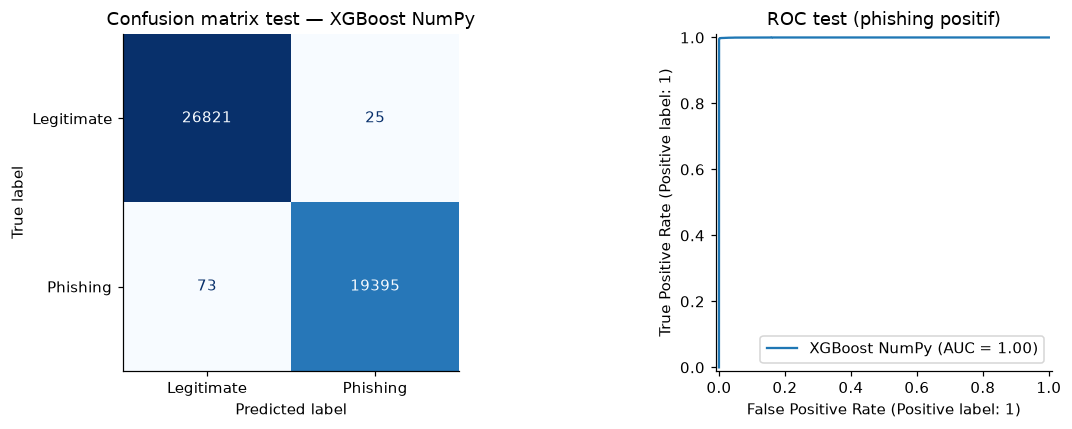

,Split,Selisih probabilitas maks,Label prediksi sama (%)
0,Train,0.0,100.0
1,Validation,0.0,100.0
2,Test,0.0,100.0


,,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
Split,Model,,,,,,,,,,,,,
Train,XGBoost library,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
Validation,XGBoost library,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
Test,XGBoost library,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395
Train,XGBoost NumPy,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
Validation,XGBoost NumPy,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
Test,XGBoost NumPy,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395


Selisih metrik maksimum library − NumPy: 0.0


,Model,Fitur akar pohon 1,Total daun 300 pohon,Waktu training (detik)
0,XGBoost library,NoOfDegitsInURL,7947,12.173494
1,XGBoost NumPy,NoOfDegitsInURL,7947,278.335407


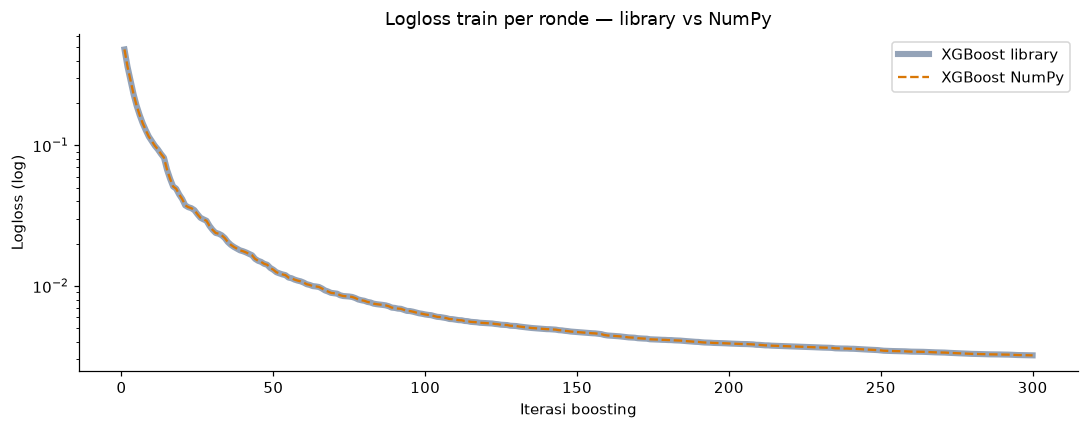

In [22]:
scratch_metrics = scratch.evaluate(matrices, labels)
agreement = pd.DataFrame([{"Split": split,
    "Selisih probabilitas maks": float(np.abs(scratch.proba_[split] - plugin.proba_[split]).max()),
    "Label prediksi sama (%)": 100 * np.mean((scratch.proba_[split] >= 0.5) == (plugin.proba_[split] >= 0.5))}
    for split in matrices])
display(agreement)
metric_cols = ["Accuracy", "Precision phishing", "Recall phishing", "F1 phishing", "Macro-F1", "FPR",
               "ROC-AUC", "PR-AUC (AP)", "Logloss", "TN", "FP", "FN", "TP"]
side_by_side = pd.concat([plugin.metrics_, scratch.metrics_]).set_index(["Split", "Model"])[metric_cols]
display(side_by_side.round(6))
difference = (plugin.metrics_.set_index("Split")[metric_cols] - scratch.metrics_.set_index("Split")[metric_cols]).abs()
print("Selisih metrik maksimum library − NumPy:", float(difference.to_numpy().max()))

lib_leaves = plugin.model.get_booster().trees_to_dataframe().query("Feature == 'Leaf'").groupby("Tree").size()
structure = pd.DataFrame({"Model": [plugin.name, scratch.name],
    "Fitur akar pohon 1": [features[int(plugin.model.get_booster().trees_to_dataframe().loc[0, "Feature"][1:])],
                           features[scratch.model.trees_[0].feature]],
    "Total daun 300 pohon": [int(lib_leaves.sum()), sum(count_leaves(t) for t in scratch.model.trees_)],
    "Waktu training (detik)": [plugin.seconds_, scratch.seconds_]})
display(structure)

library_train_curve = lr_curves[best_lr][0]
plt.plot(np.arange(1, 301), library_train_curve, label="XGBoost library", linewidth=4, color="#94a3b8")
plt.plot(np.arange(1, 301), scratch.model.loss_history_, label="XGBoost NumPy", linestyle="--", color=COLOR_PHISHING)
plt.title("Logloss train per ronde — library vs NumPy"); plt.yscale("log")
plt.xlabel("Iterasi boosting"); plt.ylabel("Logloss (log)"); plt.legend(); plt.tight_layout(); plt.show()

## Bagian 5: Baseline Decision Tree tanpa batas vs XGBoost
### Langkah 5.1: Latih Decision Tree tanpa batas
`DecisionTreeClassifier(random_state=42)` tanpa max_depth dan dengan min_samples_leaf = 1 membuat pohon tumbuh sampai daun murni. Fitur, preprocessing, dan train (asli, tanpa SMOTE) sama dengan XGBoost.

Decision Tree tanpa batas adalah baseline model pada proyek ini. Seluruh model memakai fitur AUC dan split yang sama, sehingga perbandingan ini sudah memenuhi kebutuhan baseline vs XGBoost.

Decision Tree tanpa batas: 1.20 detik; 142,748 baris latih


,Model,Kedalaman,Jumlah daun,Waktu training (detik)
0,Decision Tree tanpa batas,34,1600,1.195800
1,XGBoost library,6,7947,12.173494


,Model,Split,Baris,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
0,Decision Tree tanpa batas,Train,142748,0.999482,0.999854,0.998946,0.999400,0.999472,0.000111,0.999993,0.999990,0.001912,81093,9,65,61581
1,Decision Tree tanpa batas,Validation,45924,0.991312,0.990880,0.988119,0.989498,0.991045,0.006431,0.991354,0.984964,0.293955,26729,173,226,18796
2,Decision Tree tanpa batas,Test,46314,0.992011,0.993386,0.987569,0.990469,0.991796,0.004768,0.991888,0.987099,0.269870,26718,128,242,19226


,precision,recall,f1-score,support
Legitimate,0.991024,0.995232,0.993123,26846.000000
Phishing,0.993386,0.987569,0.990469,19468.000000
accuracy,0.992011,0.992011,0.992011,0.992011
macro avg,0.992205,0.991401,0.991796,46314.000000
weighted avg,0.992017,0.992011,0.992008,46314.000000


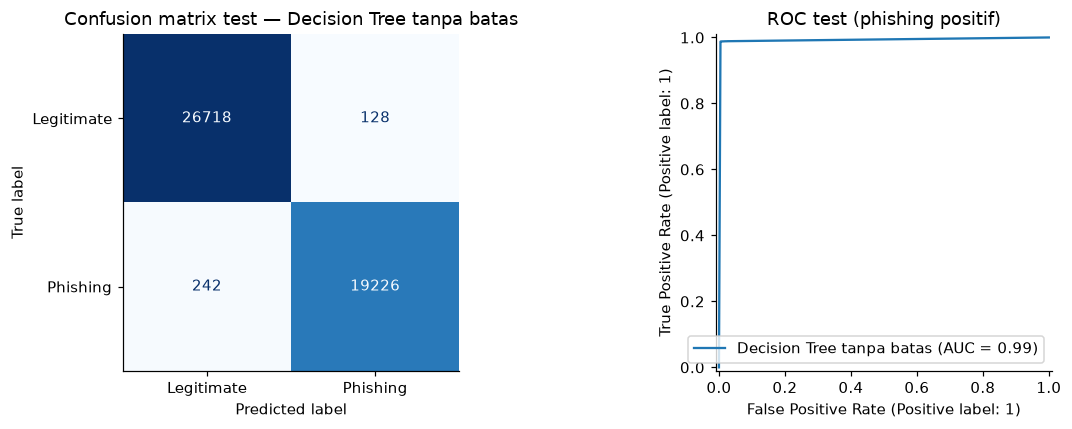

In [23]:
dt = ModelExperiment("Decision Tree tanpa batas", DecisionTreeClassifier(random_state=cfg.seed))
dt.fit(matrices["Train"], labels["Train"])
display(pd.DataFrame([{"Model": dt.name, "Kedalaman": dt.model.get_depth(), "Jumlah daun": dt.model.get_n_leaves(),
                       "Waktu training (detik)": dt.seconds_},
                      {"Model": plugin.name, "Kedalaman": cfg.max_depth, "Jumlah daun": int(lib_leaves.sum()),
                       "Waktu training (detik)": plugin.seconds_}]))
dt_metrics = dt.evaluate(matrices, labels)

### Langkah 5.2: Tabel perbandingan
Ambang phishing 0,5 berlaku untuk semua model. Gap train-test dihitung dari Macro-F1.

In [24]:
comparison = pd.concat([dt.metrics_, plugin.metrics_, scratch.metrics_], ignore_index=True)
display(comparison.round(6))
test_comparison = comparison[comparison.Split == "Test"].set_index("Model")[metric_cols].T
display(test_comparison.round(6))
gap = comparison.pivot(index="Model", columns="Split", values="Macro-F1")[["Train", "Validation", "Test"]]
gap["Gap train-test"] = gap["Train"] - gap["Test"]
display(gap.round(6))

,Model,Split,Baris,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
0,Decision Tree tanpa batas,Train,142748,0.999482,0.999854,0.998946,0.999400,0.999472,0.000111,0.999993,0.999990,0.001912,81093,9,65,61581
1,Decision Tree tanpa batas,Validation,45924,0.991312,0.990880,0.988119,0.989498,0.991045,0.006431,0.991354,0.984964,0.293955,26729,173,226,18796
2,Decision Tree tanpa batas,Test,46314,0.992011,0.993386,0.987569,0.990469,0.991796,0.004768,0.991888,0.987099,0.269870,26718,128,242,19226
3,XGBoost library,Train,142748,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
4,XGBoost library,Validation,45924,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
5,XGBoost library,Test,46314,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395
6,XGBoost NumPy,Train,142748,0.999391,0.999968,0.998621,0.999294,0.999379,0.000025,0.999982,0.999977,0.003210,81100,2,85,61561
7,XGBoost NumPy,Validation,45924,0.997126,0.997891,0.995163,0.996526,0.997037,0.001487,0.999819,0.999797,0.010324,26862,40,92,18930
8,XGBoost NumPy,Test,46314,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395


Model,Decision Tree tanpa batas,XGBoost library,XGBoost NumPy
Accuracy,0.992011,0.997884,0.997884
Precision phishing,0.993386,0.998713,0.998713
Recall phishing,0.987569,0.996250,0.996250
F1 phishing,0.990469,0.997480,0.997480
Macro-F1,0.991796,0.997828,0.997828
FPR,0.004768,0.000931,0.000931
ROC-AUC,0.991888,0.999910,0.999910
PR-AUC (AP),0.987099,0.999892,0.999892
Logloss,0.269870,0.007537,0.007537
TN,26718.000000,26821.000000,26821.000000


Split,Train,Validation,Test,Gap train-test
Model,,,,
Decision Tree tanpa batas,0.999472,0.991045,0.991796,0.007675
XGBoost NumPy,0.999379,0.997037,0.997828,0.001551
XGBoost library,0.999379,0.997037,0.997828,0.001551


### Langkah 5.3: Visualisasi perbandingan

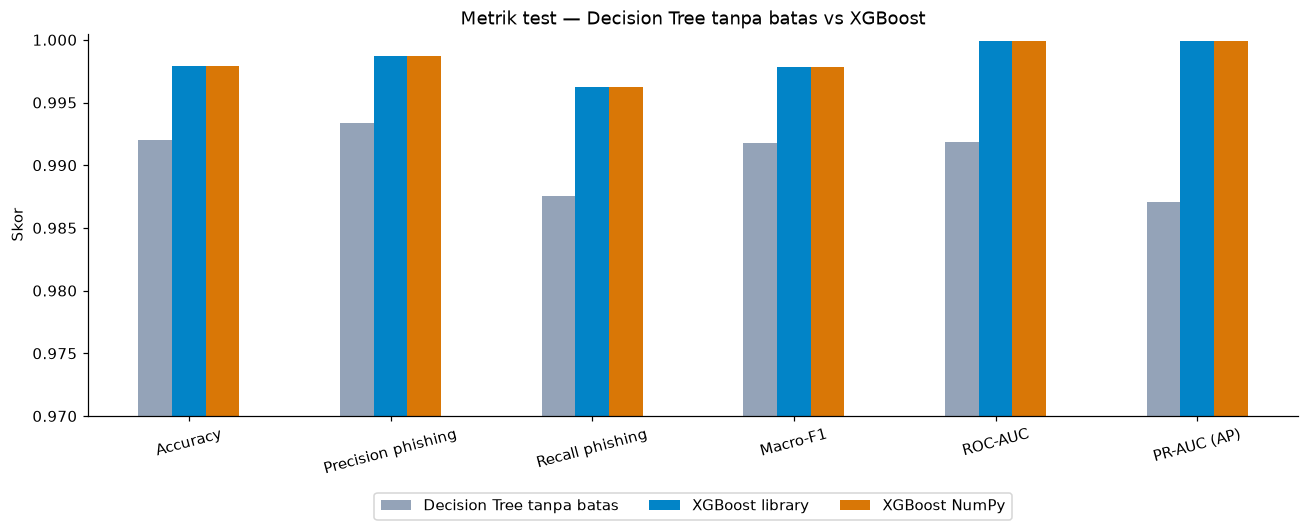

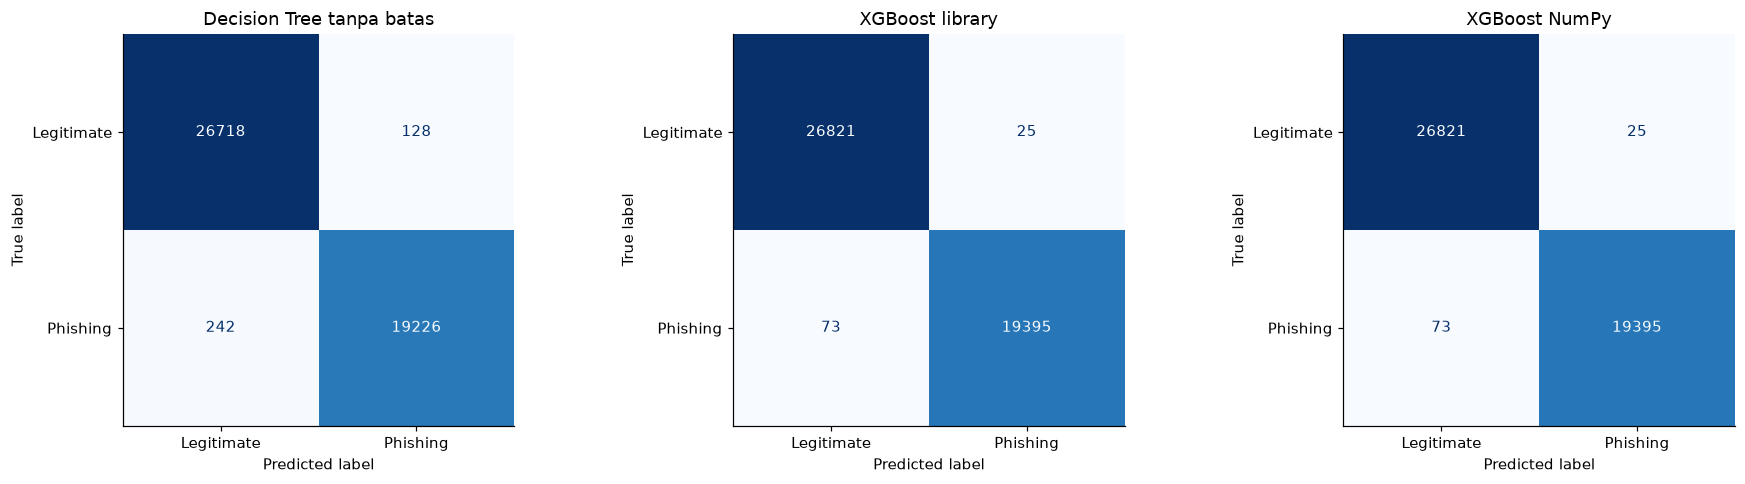

In [25]:
plot_metrics = ["Accuracy", "Precision phishing", "Recall phishing", "Macro-F1", "ROC-AUC", "PR-AUC (AP)"]
test_comparison.loc[plot_metrics].plot.bar(figsize=(12, 5), rot=15, ylim=(0.97, 1.0005),
                                           color=["#94a3b8", COLOR_LEGIT, COLOR_PHISHING])
plt.title("Metrik test — Decision Tree tanpa batas vs XGBoost"); plt.ylabel("Skor")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
actual_test = (labels["Test"] == PHISHING).astype(int)
for ax, experiment in zip(axes, [dt, plugin, scratch]):
    ConfusionMatrixDisplay.from_predictions(actual_test, (experiment.proba_["Test"] >= 0.5).astype(int),
        labels=[0, 1], display_labels=["Legitimate", "Phishing"], ax=ax, cmap="Blues", colorbar=False,
        values_format="d")
    ax.set_title(experiment.name)
plt.tight_layout(); plt.show()

### Langkah 5.4: Uji selisih dengan bootstrap per domain
URL dalam satu domain induk tidak independen, jadi test di-resample per domain induk sebanyak 1.000 kali (seed 42). Interval kepercayaan (IK) 95% memakai persentil 2,5 dan 97,5. Selisih dianggap bermakna jika IK selisihnya tidak memuat nol.

In [26]:
test_groups, group_names = pd.factorize(groups[test_idx])

def domain_bootstrap(probabilities, n_boot=1000, seed=cfg.seed):
    actual = (labels["Test"] == PHISHING).astype(int)
    cells = {}
    for name, p in probabilities.items():
        pred = (p >= 0.5).astype(int)
        masks = {"TP": (pred == 1) & (actual == 1), "FP": (pred == 1) & (actual == 0),
                 "FN": (pred == 0) & (actual == 1), "TN": (pred == 0) & (actual == 0)}
        cells[name] = {k: np.bincount(test_groups, weights=m, minlength=len(group_names)) for k, m in masks.items()}
    rng = np.random.default_rng(seed)
    draws = {name: {"Accuracy": [], "Precision phishing": [], "Recall phishing": [], "FPR": []} for name in probabilities}
    for _ in range(n_boot):
        weights = np.bincount(rng.integers(0, len(group_names), len(group_names)), minlength=len(group_names))
        for name, cell in cells.items():
            tp, fp, fn, tn = (weights @ cell[k] for k in ("TP", "FP", "FN", "TN"))
            draws[name]["Accuracy"].append((tp + tn) / (tp + fp + fn + tn))
            draws[name]["Precision phishing"].append(tp / (tp + fp))
            draws[name]["Recall phishing"].append(tp / (tp + fn))
            draws[name]["FPR"].append(fp / (fp + tn))
    return {name: {m: np.array(v) for m, v in d.items()} for name, d in draws.items()}

def difference_table(draws, first, second):
    rows = []
    for metric in draws[first]:
        delta = draws[first][metric] - draws[second][metric]
        low, high = np.percentile(delta, [2.5, 97.5])
        rows.append({"Metrik": metric, f"Selisih {first} − {second} (rata-rata)": delta.mean(),
                     "IK 95% bawah": low, "IK 95% atas": high, "Memuat nol": bool(low <= 0 <= high)})
    return pd.DataFrame(rows)

boot5 = domain_bootstrap({dt.name: dt.proba_["Test"], plugin.name: plugin.proba_["Test"]})
ci5 = pd.DataFrame([{"Model": name, "Metrik": metric, "IK 95% bawah": np.percentile(v, 2.5),
                     "IK 95% atas": np.percentile(v, 97.5)}
                    for name, d in boot5.items() for metric, v in d.items()])
display(ci5.pivot(index="Metrik", columns="Model").round(4))
display(difference_table(boot5, plugin.name, dt.name).round(4))

IK 95% bawah                               IK 95% atas                
Model              Decision Tree tanpa batas XGBoost library Decision Tree tanpa batas XGBoost library
Metrik                                                                                                
Accuracy                              0.9902          0.9974                    0.9933          0.9983
FPR                                   0.0040          0.0006                    0.0057          0.0013
Precision phishing                    0.9920          0.9981                    0.9947          0.9992
Recall phishing                       0.9840          0.9951                    0.9904          0.9972

,Metrik,Selisih XGBoost library − Decision Tree tanpa batas (rata-rata),IK 95% bawah,IK 95% atas,Memuat nol
0,Accuracy,0.0059,0.0046,0.0076,False
1,Precision phishing,0.0053,0.0043,0.0066,False
2,Recall phishing,0.0086,0.0060,0.0123,False
3,FPR,-0.0038,-0.0046,-0.0031,False


## Bagian 5B: Learning curve dan diagnosis kecocokan model
Kurva ukuran data memakai 3-fold GroupKFold pada train asli, dengan ukuran 10%, 25%, 50%, 75%, dan 100% domain dari bagian latih tiap fold. Subset bersarang dan urutan domain diacak dengan seed tetap. Fitur AUC, imputasi, dan scaler di-fit ulang pada setiap subset, dan fold evaluasi tidak ikut fit apa pun. Baseline dan XGBoost menggunakan subset yang identik. Area berwarna menunjukkan +/- 1 simpangan baku antar-fold dan tidak boleh dibaca sebagai confidence interval.

Hyperparameter dan ambang yang sudah dipilih dipertahankan, jadi kurva ini hanya mendiagnosis konfigurasi tersebut. Prosesnya tidak memakai nested CV untuk mengestimasi seleksi model. Ukuran 100% berarti semua data latih dalam fold, sekitar 2/3 train utama. Test tidak digunakan.

Kurva jumlah pohon menampilkan logloss train dan validation sepanjang boosting. Underfit terlihat jika kedua skor rendah atau kedua loss tinggi. Overfit terlihat jika train sangat baik sementara evaluasi tertinggal, atau loss validation naik ketika loss train turun. Model dianggap fit baik jika skor evaluasi tinggi dengan gap kecil. Diagnosis dilaporkan sebagai indikasi dan tidak disimpulkan dari satu titik atau satu angka ambang universal.


Fold 1, fraksi 10%, 8,686 baris, 27 fitur selesai


Fold 1, fraksi 25%, 22,498 baris, 27 fitur selesai


Fold 1, fraksi 50%, 46,090 baris, 27 fitur selesai


Fold 1, fraksi 75%, 68,654 baris, 27 fitur selesai


Fold 1, fraksi 100%, 95,165 baris, 28 fitur selesai


Fold 2, fraksi 10%, 9,899 baris, 27 fitur selesai


... (6 outputs left out)

Fold 3, fraksi 50%, 45,739 baris, 28 fitur selesai


Fold 3, fraksi 75%, 68,381 baris, 27 fitur selesai


Fold 3, fraksi 100%, 95,166 baris, 30 fitur selesai


,Model,Fraksi domain,Split,n,F1,F1_sd,AUC,AUC_sd,loss,loss_sd
0,Baseline Decision Tree,0.10,CV,9121.000000,0.964226,0.012992,0.966049,0.015121,1.132403,0.470716
1,Baseline Decision Tree,0.10,Train,9121.000000,0.996450,0.005207,0.999918,0.000135,0.006897,0.009467
2,Baseline Decision Tree,0.25,CV,22836.666667,0.980414,0.015345,0.979003,0.017241,0.681104,0.533838
3,Baseline Decision Tree,0.25,Train,22836.666667,0.999441,0.000025,0.999993,0.000006,0.001846,0.000323
4,Baseline Decision Tree,0.50,CV,45920.000000,0.985423,0.000918,0.984963,0.001021,0.503988,0.030656
5,Baseline Decision Tree,0.50,Train,45920.000000,0.999424,0.000101,0.999991,0.000009,0.001940,0.000574
6,Baseline Decision Tree,0.75,CV,69657.333333,0.989276,0.000904,0.989023,0.001174,0.363385,0.034356
7,Baseline Decision Tree,0.75,Train,69657.333333,0.999378,0.000086,0.999986,0.000011,0.002301,0.000533
8,Baseline Decision Tree,1.00,CV,95165.333333,0.992032,0.003050,0.992051,0.003201,0.268659,0.105499
9,Baseline Decision Tree,1.00,Train,95165.333333,0.999504,0.000082,0.999993,0.000003,0.001810,0.000313


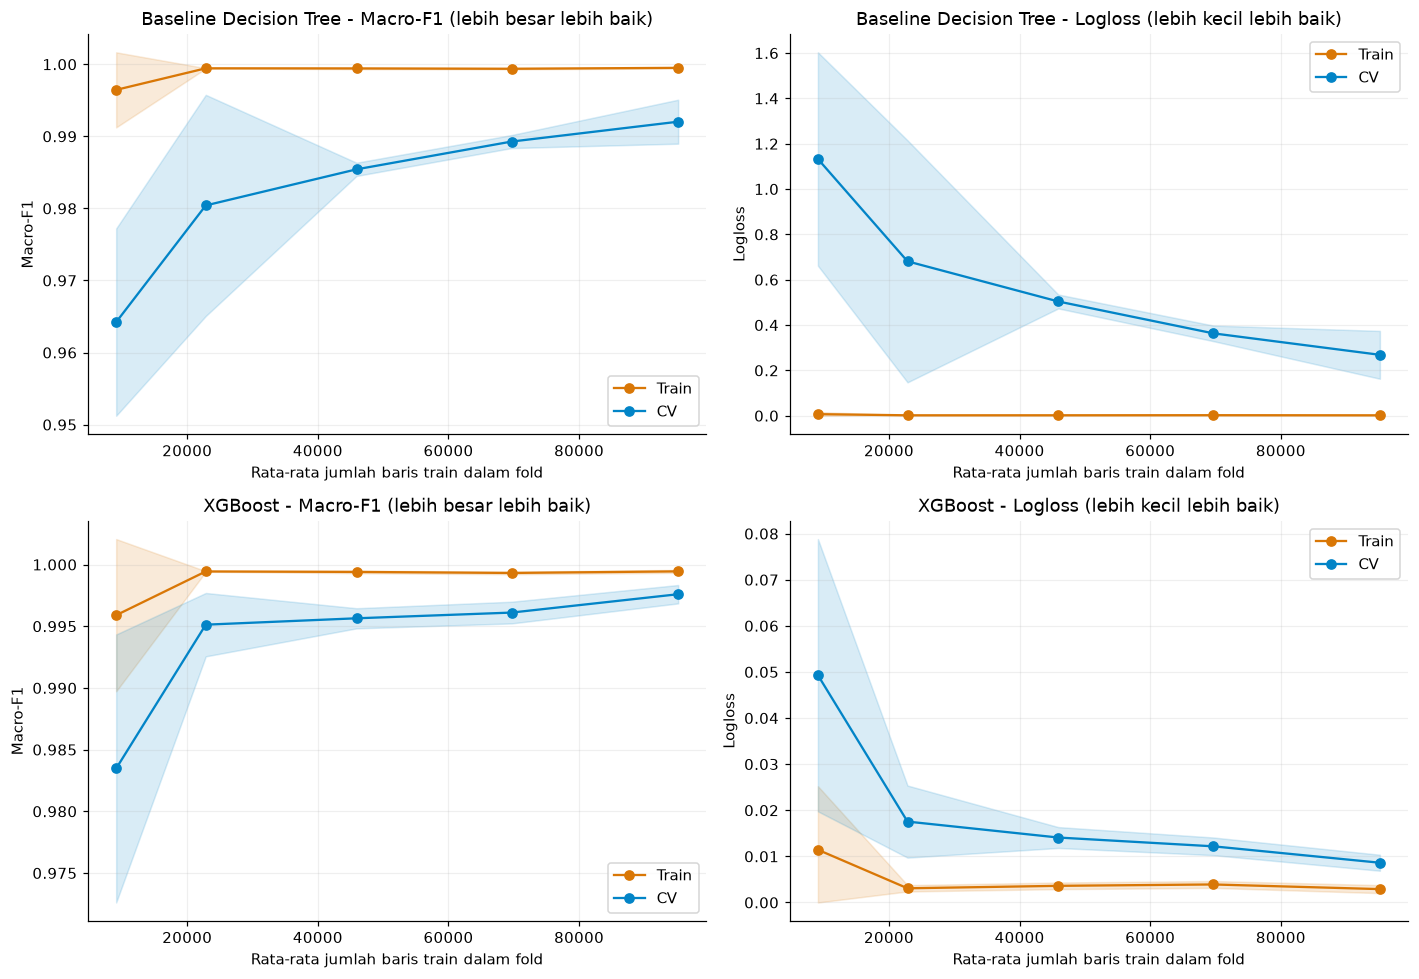

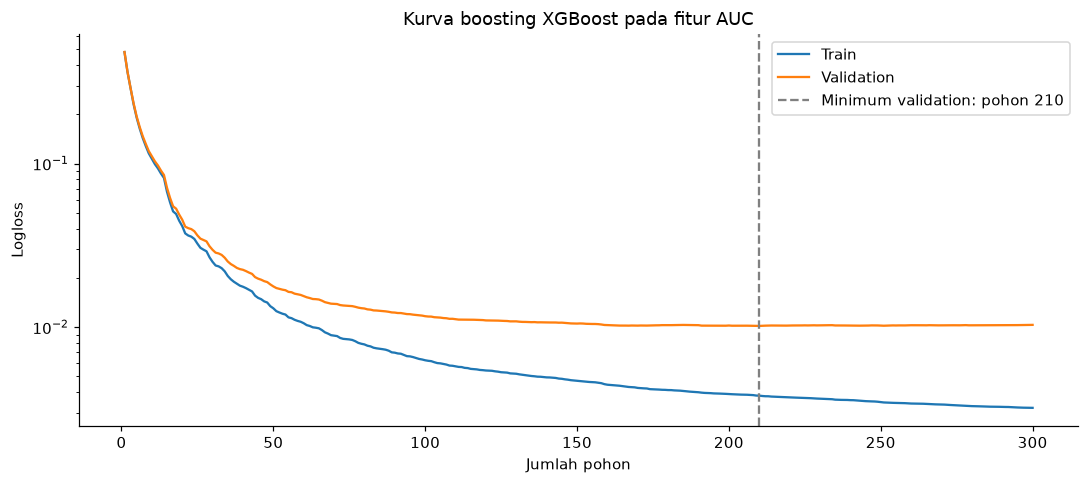

Baseline Decision Tree: F1 train=0.999504, CV=0.992032, gap=0.007472; loss train=0.001810, CV=0.268659
XGBoost: F1 train=0.999447, CV=0.997595, gap=0.001852; loss train=0.002896, CV=0.008618
XGBoost: minimum validation loss=0.010171 di pohon 210; loss akhir=0.010324; kenaikan setelah minimum=0.000152
Tafsirkan gap, level kinerja, variasi fold dan arah kurva bersama-sama; gap kecil saja tidak cukup membuktikan fit.


In [27]:
fractions = (0.10, 0.25, 0.50, 0.75, 1.0)
cv = GroupKFold(n_splits=3)
curve_rows = []
base_indices = np.asarray(train_idx)
for fold, (fit_rel, eval_rel) in enumerate(cv.split(X.iloc[train_idx], y[train_idx], groups[train_idx]), start=1):
    fit_idx, eval_idx = base_indices[fit_rel], base_indices[eval_rel]
    rng = np.random.default_rng(cfg.seed + fold)
    domain_order = rng.permutation(np.unique(groups[fit_idx]))
    for fraction in fractions:
        use_domains = domain_order[:max(2, int(np.ceil(fraction * len(domain_order))))]
        sub_idx = fit_idx[pd.Series(groups[fit_idx]).isin(use_domains).to_numpy()]
        assert not set(groups[sub_idx]) & set(groups[eval_idx])
        assert len(np.unique(y[sub_idx])) == len(np.unique(y[eval_idx])) == 2
        local_selector = FeatureSelector().fit(X.iloc[sub_idx], y[sub_idx])
        columns = local_selector.select(best_threshold)
        pp = Preprocessor().fit(X[columns].iloc[sub_idx])
        a, b = pp.transform(X[columns].iloc[sub_idx]), pp.transform(X[columns].iloc[eval_idx])
        models = {"Baseline Decision Tree": DecisionTreeClassifier(random_state=cfg.seed),
                  "XGBoost": make_xgb(learning_rate=best_lr)}
        for name, model in models.items():
            model.fit(a, y[sub_idx])
            for split, matrix, truth in [("Train", a, y[sub_idx]), ("CV", b, y[eval_idx])]:
                metrics = phishing_metrics(truth, phishing_probability(model, matrix))
                curve_rows.append({"Model": name, "Fold": fold, "Fraksi domain": fraction,
                    "Jumlah baris train": len(sub_idx), "Jumlah fitur": len(columns), "Split": split,
                    **{m: metrics[m] for m in ["Macro-F1", "ROC-AUC", "Logloss"]}})
        print(f"Fold {fold}, fraksi {fraction:.0%}, {len(sub_idx):,} baris, {len(columns)} fitur selesai", flush=True)
curve_table = pd.DataFrame(curve_rows)
curve_table.to_csv(OUT / "learning_curve.csv", index=False)
curve_summary = curve_table.groupby(["Model", "Fraksi domain", "Split"], as_index=False).agg(
    n=("Jumlah baris train", "mean"), F1=("Macro-F1", "mean"), F1_sd=("Macro-F1", "std"),
    AUC=("ROC-AUC", "mean"), AUC_sd=("ROC-AUC", "std"), loss=("Logloss", "mean"), loss_sd=("Logloss", "std"))
display(curve_summary.round(6))
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, name in enumerate(["Baseline Decision Tree", "XGBoost"]):
    for col, (metric, sd, title) in enumerate([("F1", "F1_sd", "Macro-F1 (lebih besar lebih baik)"),
                                             ("loss", "loss_sd", "Logloss (lebih kecil lebih baik)")]):
        ax = axes[row, col]
        for split, color in [("Train", "#d97706"), ("CV", "#0284c7")]:
            q = curve_summary[(curve_summary.Model == name) & (curve_summary.Split == split)].sort_values("n")
            xx, yy, ss = q.n.to_numpy(), q[metric].to_numpy(), q[sd].to_numpy()
            ax.plot(xx, yy, "o-", label=split, color=color)
            ax.fill_between(xx, np.maximum(0, yy-ss), yy+ss, color=color, alpha=.15)
        ax.set(title=f"{name} - {title}", xlabel="Rata-rata jumlah baris train dalam fold", ylabel=title.split(" (")[0])
        ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT / "learning_curve_ukuran_data.png", dpi=180, bbox_inches="tight")
plt.show()

tr, va = lr_curves[best_lr]
best_round = int(va.argmin()+1)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(np.arange(1,len(tr)+1), tr, label="Train")
ax.plot(np.arange(1,len(va)+1), va, label="Validation")
ax.axvline(best_round, color="grey", linestyle="--", label=f"Minimum validation: pohon {best_round}")
ax.set(xlabel="Jumlah pohon", ylabel="Logloss", yscale="log", title="Kurva boosting XGBoost pada fitur AUC")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "learning_curve_boosting.png", dpi=180, bbox_inches="tight"); plt.show()
for name in curve_summary.Model.unique():
    last = curve_summary[(curve_summary.Model == name) & (curve_summary["Fraksi domain"] == 1.0)].set_index("Split")
    print(f"{name}: F1 train={last.loc['Train','F1']:.6f}, CV={last.loc['CV','F1']:.6f}, "
          f"gap={last.loc['Train','F1']-last.loc['CV','F1']:.6f}; "
          f"loss train={last.loc['Train','loss']:.6f}, CV={last.loc['CV','loss']:.6f}")
print(f"XGBoost: minimum validation loss={va.min():.6f} di pohon {best_round}; "
      f"loss akhir={va[-1]:.6f}; kenaikan setelah minimum={va[-1]-va.min():.6f}")
print("Tafsirkan gap, level kinerja, variasi fold dan arah kurva bersama-sama; gap kecil saja tidak cukup membuktikan fit.")


## Bagian 6: XGBoost dengan SMOTE dibandingkan sebelum SMOTE
### Langkah 6.1: Terapkan SMOTE pada train
SMOTE (`k_neighbors` = 5, `random_state` = 42, `sampling_strategy` = 1,0) hanya diterapkan pada train yang sudah diimputasi dan di-scale. Validation dan test tetap dalam distribusi asli. Interpolasi SMOTE dapat membuat fitur biner bernilai pecahan, jadi jumlahnya diperiksa.

,Sebelum SMOTE,Sesudah SMOTE,Penambahan
Phishing (0),61646,81102,19456
Legitimate (1),81102,81102,0
Total,142748,162204,19456


k_neighbors = 5, rasio legitimate : phishing sebelum SMOTE = 1.3156 : 1


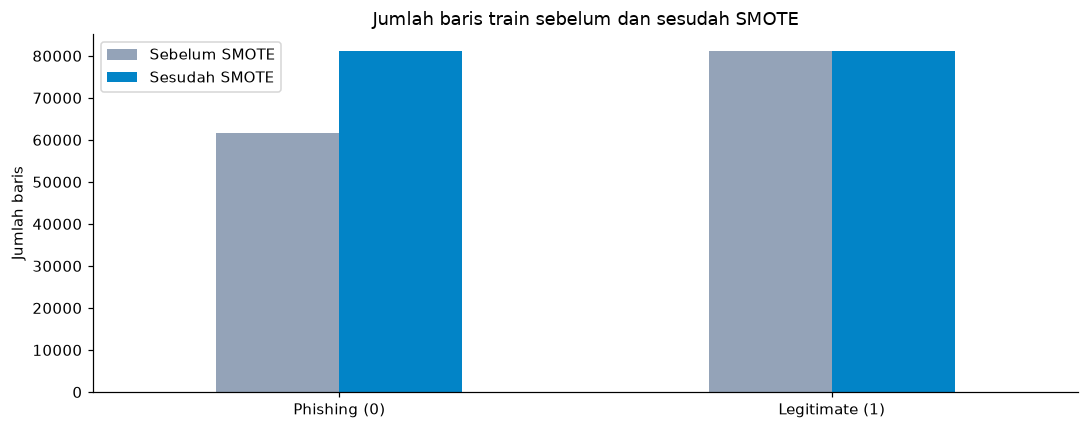

Fitur biner: 13 | baris sintetis: 19,456 | baris dengan nilai biner pecahan: 508 (2.61%)


,IsDomainIP,HasObfuscation,HasTitle,HasFavicon,Robots,NoOfURLRedirect,NoOfSelfRedirect,HasExternalFormSubmit,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto
% baris sintetis pecahan,0.0,0.0,0.26,0.66,0.43,0.28,0.03,0.04,0.86,0.19,0.2,0.63,0.01


In [28]:
counts_before = np.bincount(labels["Train"], minlength=2)
smote = SMOTE(sampling_strategy=1.0, k_neighbors=min(5, int(counts_before.min()) - 1), random_state=cfg.seed)
X_smote, y_smote = smote.fit_resample(matrices["Train"], labels["Train"])
counts_after = np.bincount(y_smote, minlength=2)
smote_counts = pd.DataFrame({"Sebelum SMOTE": counts_before, "Sesudah SMOTE": counts_after},
                            index=[LABEL_NAMES[0], LABEL_NAMES[1]])
smote_counts["Penambahan"] = smote_counts["Sesudah SMOTE"] - smote_counts["Sebelum SMOTE"]
smote_counts.loc["Total"] = smote_counts.sum()
display(smote_counts)
print(f"k_neighbors = {smote.k_neighbors}, rasio legitimate : phishing sebelum SMOTE = "
      f"{counts_before[1 - PHISHING] / counts_before[PHISHING]:.4f} : 1")
assert counts_after[0] == counts_after[1]

smote_counts.drop(index="Total")[["Sebelum SMOTE", "Sesudah SMOTE"]].plot.bar(rot=0, color=["#94a3b8", COLOR_LEGIT])
plt.title("Jumlah baris train sebelum dan sesudah SMOTE"); plt.ylabel("Jumlah baris"); plt.tight_layout(); plt.show()

binary_features = [c for c in features if set(np.unique(X[c].iloc[train_idx])) <= {0, 1}]
synthetic = preprocessor.scaler.inverse_transform(X_smote[len(labels["Train"]):])
columns = [features.index(c) for c in binary_features]
fractional = np.abs(synthetic[:, columns] - np.round(synthetic[:, columns])) > 1e-4
print(f"Fitur biner: {len(binary_features)} | baris sintetis: {len(synthetic):,} | baris dengan nilai biner pecahan: "
      f"{fractional.any(axis=1).sum():,} ({100 * fractional.any(axis=1).mean():.2f}%)")
display(pd.Series(100 * fractional.mean(axis=0), index=binary_features, name="% baris sintetis pecahan").round(2).to_frame().T)

### Langkah 6.2: Latih XGBoost pada train hasil SMOTE
Parameternya sama persis dengan XGBoost library pada Bagian 3, dan yang berbeda hanya data latihnya. Metrik train tetap dihitung pada train asli.

XGBoost + SMOTE: 14.55 detik; 162,204 baris latih


,Model,Split,Baris,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP
0,XGBoost + SMOTE,Train,142748,0.999363,0.999919,0.998605,0.999261,0.999350,0.000062,0.999983,0.999978,0.003150,81097,5,86,61560
1,XGBoost + SMOTE,Validation,45924,0.997256,0.997682,0.995689,0.996685,0.997172,0.001636,0.999783,0.999760,0.010583,26858,44,82,18940
2,XGBoost + SMOTE,Test,46314,0.997754,0.998507,0.996148,0.997326,0.997695,0.001080,0.999926,0.999907,0.007297,26817,29,75,19393


,precision,recall,f1-score,support
Legitimate,0.997211,0.998920,0.998065,26846.000000
Phishing,0.998507,0.996148,0.997326,19468.000000
accuracy,0.997754,0.997754,0.997754,0.997754
macro avg,0.997859,0.997534,0.997695,46314.000000
weighted avg,0.997756,0.997754,0.997754,46314.000000


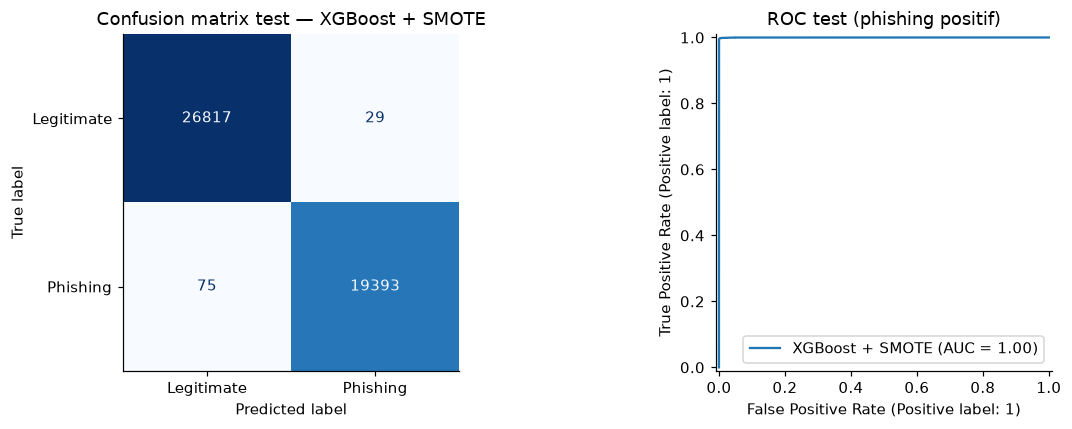

In [29]:
smote_xgb = ModelExperiment("XGBoost + SMOTE", make_xgb(learning_rate=best_lr))
smote_xgb.fit(X_smote, y_smote)
smote_metrics = smote_xgb.evaluate(matrices, labels)

### Langkah 6.3: Bandingkan sebelum dan sesudah SMOTE

Validation:


Data,Sebelum SMOTE,Sesudah SMOTE,Selisih (sesudah − sebelum)
Accuracy,0.997126,0.997256,0.000131
Precision phishing,0.997891,0.997682,-0.000209
Recall phishing,0.995163,0.995689,0.000526
F1 phishing,0.996526,0.996685,0.000159
Macro-F1,0.997037,0.997172,0.000135
FPR,0.001487,0.001636,0.000149
ROC-AUC,0.999819,0.999783,-0.000036
PR-AUC (AP),0.999797,0.999760,-0.000037
Logloss,0.010324,0.010583,0.000260
TN,26862.000000,26858.000000,-4.000000


Test:


Data,Sebelum SMOTE,Sesudah SMOTE,Selisih (sesudah − sebelum)
Accuracy,0.997884,0.997754,-0.000130
Precision phishing,0.998713,0.998507,-0.000206
Recall phishing,0.996250,0.996148,-0.000103
F1 phishing,0.997480,0.997326,-0.000154
Macro-F1,0.997828,0.997695,-0.000133
FPR,0.000931,0.001080,0.000149
ROC-AUC,0.999910,0.999926,0.000016
PR-AUC (AP),0.999892,0.999907,0.000015
Logloss,0.007537,0.007297,-0.000240
TN,26821.000000,26817.000000,-4.000000


,Data,Rata-rata P(phishing) test,Prediksi phishing test,Phishing sebenarnya test
0,Sebelum SMOTE,0.419967,19420,19468
1,Sesudah SMOTE,0.420095,19422,19468


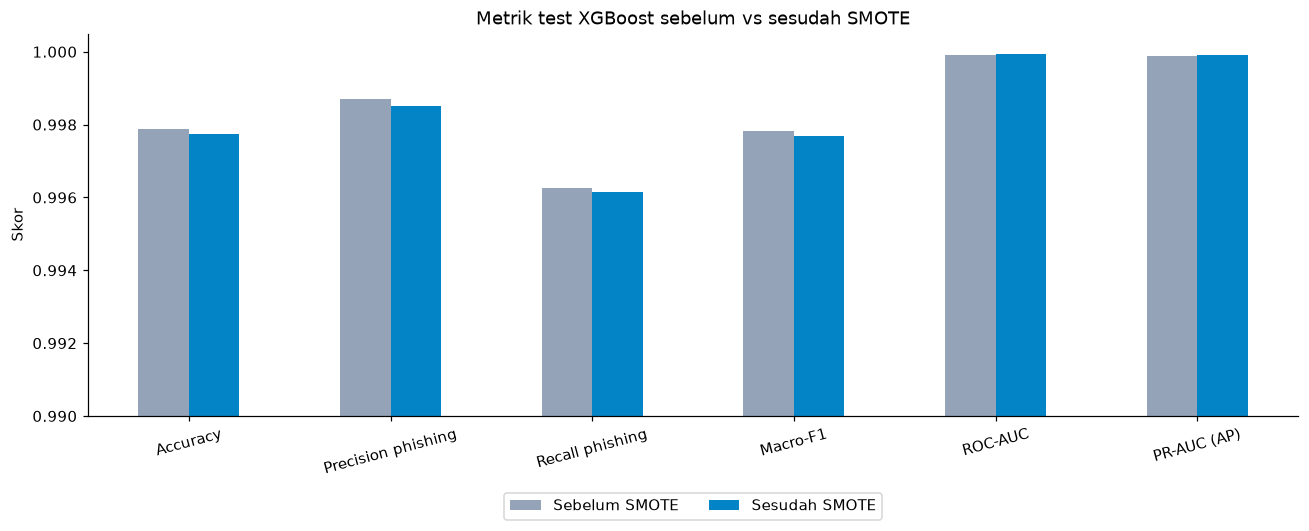

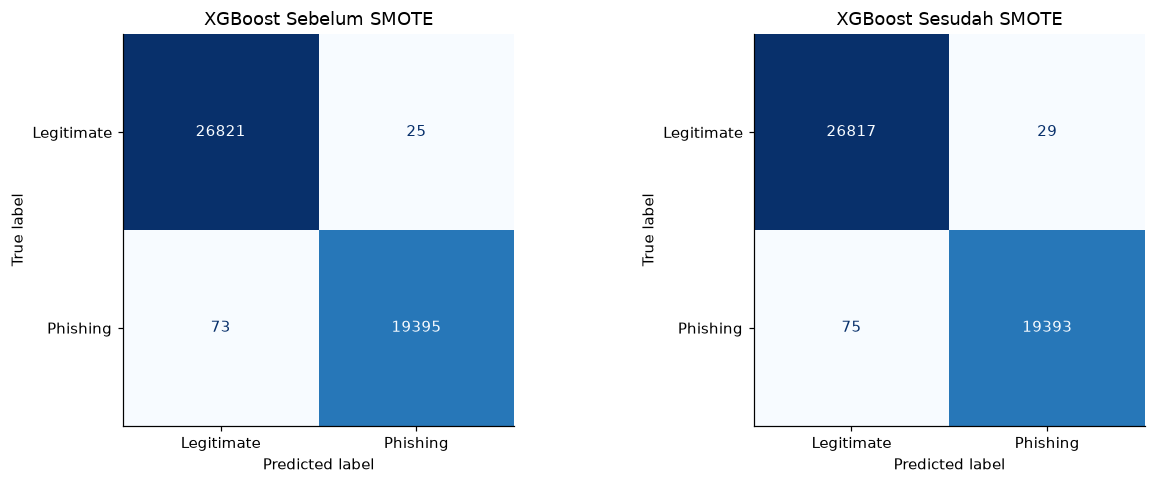

,Metrik,Selisih Sesudah SMOTE − Sebelum SMOTE (rata-rata),IK 95% bawah,IK 95% atas,Memuat nol
0,Accuracy,-0.0001,-0.0003,0.0001,True
1,Precision phishing,-0.0002,-0.0005,0.0001,True
2,Recall phishing,-0.0001,-0.0005,0.0003,True
3,FPR,0.0001,-0.0001,0.0004,True


In [30]:
before_after = pd.concat([plugin.metrics_.assign(Data="Sebelum SMOTE"), smote_xgb.metrics_.assign(Data="Sesudah SMOTE")])
for split in ["Validation", "Test"]:
    table = before_after[before_after.Split == split].set_index("Data")[metric_cols].T
    table["Selisih (sesudah − sebelum)"] = table["Sesudah SMOTE"] - table["Sebelum SMOTE"]
    print(f"{split}:")
    display(table.round(6))

probability_shift = pd.DataFrame({"Data": ["Sebelum SMOTE", "Sesudah SMOTE"],
    "Rata-rata P(phishing) test": [plugin.proba_["Test"].mean(), smote_xgb.proba_["Test"].mean()],
    "Prediksi phishing test": [int((plugin.proba_["Test"] >= 0.5).sum()), int((smote_xgb.proba_["Test"] >= 0.5).sum())],
    "Phishing sebenarnya test": [int((labels["Test"] == PHISHING).sum())] * 2})
display(probability_shift.round(6))

test_table = before_after[before_after.Split == "Test"].set_index("Data")[plot_metrics].T
test_table.plot.bar(figsize=(12, 5), rot=15, ylim=(0.99, 1.0005), color=["#94a3b8", COLOR_LEGIT])
plt.title("Metrik test XGBoost sebelum vs sesudah SMOTE"); plt.ylabel("Skor")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, experiment) in zip(axes, [("Sebelum SMOTE", plugin), ("Sesudah SMOTE", smote_xgb)]):
    ConfusionMatrixDisplay.from_predictions(actual_test, (experiment.proba_["Test"] >= 0.5).astype(int),
        labels=[0, 1], display_labels=["Legitimate", "Phishing"], ax=ax, cmap="Blues", colorbar=False,
        values_format="d")
    ax.set_title(f"XGBoost {title}")
plt.tight_layout(); plt.show()

boot6 = domain_bootstrap({"Sesudah SMOTE": smote_xgb.proba_["Test"], "Sebelum SMOTE": plugin.proba_["Test"]})
display(difference_table(boot6, "Sesudah SMOTE", "Sebelum SMOTE").round(4))

### Ringkasan hasil test jalur AUC (RFE pada Langkah 3.2b)

In [31]:
summary = pd.concat([plugin.metrics_, scratch.metrics_, dt.metrics_, smote_xgb.metrics_])
summary = summary[summary.Split == "Test"].set_index("Model")[metric_cols]
summary["Memenuhi target bisnis"] = [meets_target(row) for _, row in summary.iterrows()]
display(summary.round(6))
# Nilai acuan hanya untuk verifikasi, bukan pengganti hasil model.
REFERENCE_TEST_METRICS = {'XGBoost library': {'Accuracy': 0.997884, 'Precision phishing': 0.998713, 'Recall phishing': 0.99625, 'F1 phishing': 0.99748, 'Macro-F1': 0.997828, 'FPR': 0.000931, 'ROC-AUC': 0.99991, 'PR-AUC (AP)': 0.999892, 'Logloss': 0.007537, 'TN': 26821, 'FP': 25, 'FN': 73, 'TP': 19395}, 'XGBoost NumPy': {'Accuracy': 0.997884, 'Precision phishing': 0.998713, 'Recall phishing': 0.99625, 'F1 phishing': 0.99748, 'Macro-F1': 0.997828, 'FPR': 0.000931, 'ROC-AUC': 0.99991, 'PR-AUC (AP)': 0.999892, 'Logloss': 0.007537, 'TN': 26821, 'FP': 25, 'FN': 73, 'TP': 19395}, 'Decision Tree tanpa batas': {'Accuracy': 0.992011, 'Precision phishing': 0.993386, 'Recall phishing': 0.987569, 'F1 phishing': 0.990469, 'Macro-F1': 0.991796, 'FPR': 0.004768, 'ROC-AUC': 0.991888, 'PR-AUC (AP)': 0.987099, 'Logloss': 0.26987, 'TN': 26718, 'FP': 128, 'FN': 242, 'TP': 19226}, 'XGBoost + SMOTE': {'Accuracy': 0.997754, 'Precision phishing': 0.998507, 'Recall phishing': 0.996148, 'F1 phishing': 0.997326, 'Macro-F1': 0.997695, 'FPR': 0.00108, 'ROC-AUC': 0.999926, 'PR-AUC (AP)': 0.999907, 'Logloss': 0.007297, 'TN': 26817, 'FP': 29, 'FN': 75, 'TP': 19393}}
verification_rows = []
for name, expected in REFERENCE_TEST_METRICS.items():
    for metric, reference_value in expected.items():
        actual_value = float(summary.loc[name, metric])
        tolerance = 0.0 if metric in {"TN", "FP", "FN", "TP"} else 5.1e-7
        verification_rows.append({"Model": name, "Metrik": metric, "Hasil run": actual_value,
                                  "Acuan laporan": reference_value,
                                  "Sesuai": abs(actual_value - reference_value) <= tolerance})
verification = pd.DataFrame(verification_rows)
verification.to_csv(OUT / "verifikasi_laporan.csv", index=False)
differences = verification.loc[~verification["Sesuai"]]
if not differences.empty:
    display(differences)
    raise RuntimeError("Ada metrik yang berbeda dari pembulatan laporan. Lihat verifikasi_laporan.csv.")
assert best_round == 210, "Ronde minimum validation loss berbeda dari laporan."
print(f"LULUS: {len(verification)} metrik test sesuai laporan pada pembulatan enam desimal.")
print("Waktu pelatihan diukur ulang dan dapat berbeda dari waktu pada laporan.")


,Accuracy,Precision phishing,Recall phishing,F1 phishing,Macro-F1,FPR,ROC-AUC,PR-AUC (AP),Logloss,TN,FP,FN,TP,Memenuhi target bisnis
Model,,,,,,,,,,,,,,
XGBoost library,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395,True
XGBoost NumPy,0.997884,0.998713,0.996250,0.997480,0.997828,0.000931,0.999910,0.999892,0.007537,26821,25,73,19395,True
Decision Tree tanpa batas,0.992011,0.993386,0.987569,0.990469,0.991796,0.004768,0.991888,0.987099,0.269870,26718,128,242,19226,True
XGBoost + SMOTE,0.997754,0.998507,0.996148,0.997326,0.997695,0.001080,0.999926,0.999907,0.007297,26817,29,75,19393,True


LULUS: 52 metrik test sesuai laporan pada pembulatan enam desimal.
Waktu pelatihan diukur ulang dan dapat berbeda dari waktu pada laporan.


## Hasil aktual dan diagnosis

| Metode seleksi | Jumlah fitur | Macro-F1 test | ROC-AUC test | Logloss test |
|---|---:|---:|---:|---:|
| AUC dua arah | 29 | 0.997828 | 0.999910 | 0.007537 |
| RFE | 29 | 0.999934 | 1.000000 | 0.000292 |

- Baseline yang dipakai adalah Decision Tree tanpa batas, sehingga tidak ada baseline duplikat yang ditambahkan.
- XGBoost memperoleh Macro-F1 train/CV pada ukuran penuh dalam fold sebesar 0.999415/0.997700. Generalisasinya tinggi dan tidak terlihat underfit berat. Loss validation minimum 0.010171 tercapai pada pohon 210, lalu menjadi 0.010324 pada pohon 300, yang menunjukkan indikasi overfit ringan pada ronde akhir.
- Decision Tree memperoleh Macro-F1 train/CV 0.999500/0.991717 dan logloss train/CV 0.001832/0.281906. Indikasi overfit-nya lebih kuat daripada XGBoost.
- Pada perbandingan AUC vs RFE, nilai prediksi dan konsentrasi gain dibaca bersama. Uji signifikansi selisih kedua metode seleksi tidak dilakukan. Jalur AUC dipertahankan untuk konsistensi rancangan, dan pilihan ini tidak ditentukan dari test.

## Ringkasan dan batas interpretasi
- Tabel AUC vs RFE menguji dua tujuan seleksi, yaitu pembatasan dominasi dan pemilihan fitur prediktif multivariat. RFE memperoleh informasi dari model dan bisa mempertahankan fitur dengan AUC univariat tinggi.
- Decision Tree tanpa batas merupakan baseline yang sudah tersedia. Nilai test hanya dipakai untuk laporan dan tidak dipakai untuk memilih model atau mengubah parameter.
- Kurva ukuran data membantu membaca variasi dan generalisasi antar-domain. Kurva boosting membantu melihat kapan penambahan pohon mulai menaikkan loss validation.
- Eksperimen ini berupa grouped hold-out ditambah diagnosis GroupKFold pada train. Evaluasinya tidak temporal, belum membuktikan bebas dari semua jenis leakage, dan tidak menjamin performa pada phishing masa depan.

Sumber: [UCI PhiUSIIL](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), [RFE scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html), [Learning curve scikit-learn](https://scikit-learn.org/stable/modules/learning_curve.html).

In [32]:
import json
threshold_table.to_csv(OUT / "ambang_auc.csv", index=False)
lr_table.to_csv(OUT / "learning_rate.csv", index=False)
comparison.to_csv(OUT / "baseline_vs_xgboost.csv", index=False)
summary.to_csv(OUT / "ringkasan_test.csv")
pd.Series(audit).to_json(OUT / "audit.json")
with open(OUT / "metadata.json", "w") as f:
    json.dump({"best_threshold": best_threshold, "best_lr": best_lr, "auc_features": auc_features,
               "rfe_features": rfe_features, "eligible": eligible, "rfe_seconds": rfe_seconds,
               "best_round": best_round, "validation_min_loss": float(va.min()),
               "validation_final_loss": float(va[-1]), "train_final_loss": float(tr[-1]),
               "split_sizes": {name: len(idx) for name,idx in parts.items()}}, f, indent=2)

np.savez_compressed(OUT / "split_laporan.npz", train_idx=train_idx, valid_idx=valid_idx,
                    test_idx=test_idx, groups=groups.astype(str))
with open(OUT / "reproduksi_laporan.json", "w", encoding="utf-8") as f:
    json.dump({"dataset_sha256": DATASET_SHA256, "versions": installed,
               "support_versions": {name: metadata.version(name) for name in ["matplotlib", "ipython", "scipy"]},
               "seed": cfg.seed, "split_sizes": actual_split,
               "best_threshold": best_threshold, "best_lr": best_lr,
               "test_metrics_checked": len(verification), "test_metrics_match_report": True,
               "report": "Laporan_Milestone_1_Humanize_dan_Daftar_Pustaka.docx"}, f, indent=2)
print("Selesai. Tabel, grafik, split, dan verifikasi tersimpan di:", OUT.resolve())


Selesai. Tabel, grafik, split, dan verifikasi tersimpan di: D:\mikroskil\MachineLearning\UTS\hasil_revisi


## Referensi metode
Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. Journal of Artificial Intelligence Research, 16, 321–357. https://doi.org/10.1613/jair.953
Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785–794. https://doi.org/10.1145/2939672.2939785
imbalanced-learn. (t.t.). Common pitfalls and recommended practices. Diakses 8 November 2026, dari https://imbalanced-learn.org/stable/common_pitfalls.html
Prasad, A., & Chandra, S. (2024). PhiUSIIL Phishing URL (Website) [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+website+dataset
scikit-learn. (t.t.). Feature selection. Diakses 8 November 2026, dari https://scikit-learn.org/stable/modules/feature_selection.html
XGBoost. (t.t.). Python API Reference: Booster.get_score. Diakses 8 November 2026, dari https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.get_score


Reproduksi laporan memeriksa environment sebelum impor, hash dataset, pemisahan domain, hasil pemilihan ambang dan learning rate, serta metrik test. Semua metrik dihitung dari hasil fit model. `verifikasi_laporan.csv` mencatat perbandingan hasil run dengan angka laporan; waktu pelatihan mengikuti perangkat saat run.

### Catatan hasil reproduksi pada Windows
Pengujian ulang 9 November 2026 menghasilkan 52 metrik test yang sama dengan pembulatan laporan, termasuk jumlah TN, FP, FN, dan TP yang identik. Pembagian utama tetap 142.748 / 45.924 / 46.314 baris; ambang AUC 0,75, 29 fitur, dan learning rate 0,3.

Learning curve ukuran penuh menghasilkan Macro-F1 CV Decision Tree 0,992032 (laporan 0,991717) dan XGBoost 0,997595 (laporan 0,997700). Selisih kecil pada learning curve, pangsa gain, probabilitas NumPy/library, serta waktu pelatihan dicatat sebagai variasi hasil run. Seluruh tabel dan grafik pada notebook ini berasal dari perhitungan aktual.
